In [7]:
import os

print(os.listdir("/content"))

['.config', 'flower_project', 'sample_data']


In [5]:
import os

oxford_path = "/content/flower_project/oxford_flowers"

os.makedirs(oxford_path, exist_ok=True)

In [6]:
!wget -P /content/flower_project/oxford_flowers https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz

!wget -P /content/flower_project/oxford_flowers https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat

!wget -P /content/flower_project/oxford_flowers https://www.robots.ox.ac.uk/~vgg/data/flowers/102/setid.mat

--2026-11-26 19:37:28--  https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz
Resolving www.robots.ox.ac.uk (www.robots.ox.ac.uk)... 129.67.94.2
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://thor.robots.ox.ac.uk/flowers/102/102flowers.tgz [following]
--2026-11-26 19:37:29--  https://thor.robots.ox.ac.uk/flowers/102/102flowers.tgz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 344862509 (329M) [application/octet-stream]
Saving to: ‘/content/flower_project/oxford_flowers/102flowers.tgz’

102flowers.tgz      100%[===================>] 328.89M  21.9MB/s    in 16s     

2026-11-26 19:37:47 (20.3 MB/s) - ‘/content/flower_project/oxford_flowers/102flowers.tgz’ saved [344862509/344862509]

--2026-1

In [9]:
print(os.listdir(oxford_path))

['setid.mat', '102flowers.tgz', 'imagelabels.mat']


In [10]:
import os
import tarfile

oxford_path = "/content/flower_project/oxford_flowers"

with tarfile.open(oxford_path + "/102flowers.tgz", "r:gz") as file:
    file.extractall(oxford_path, filter="data")

print("Oxford dataset extracted successfully!")

Oxford dataset extracted successfully!


In [11]:
image_path = oxford_path + "/jpg"

images = sorted([
    f for f in os.listdir(image_path)
    if f.endswith(".jpg")
])

print("Total images:", len(images))
print("First 5 images:", images[:5])

Total images: 8189
First 5 images: ['image_00001.jpg', 'image_00002.jpg', 'image_00003.jpg', 'image_00004.jpg', 'image_00005.jpg']


In [12]:
from scipy.io import loadmat
import numpy as np

labels = loadmat(oxford_path + "/imagelabels.mat")
labels = labels["labels"].flatten()

print("Total labels:", len(labels))
print("Number of classes:", len(np.unique(labels)))
print("First 10 labels:", labels[:10])

assert len(images) == len(labels)

Total labels: 8189
Number of classes: 102
First 10 labels: [77 77 77 77 77 77 77 77 77 77]


In [13]:
flower_names = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells",
    "sweet pea", "english marigold", "tiger lily", "moon orchid",
    "bird of paradise", "monkshood", "globe thistle", "snapdragon",
    "colt's foot", "king protea", "spear thistle", "yellow iris",
    "globe-flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower",
    "fritillary", "red ginger", "grape hyacinth", "corn poppy",
    "prince of wales feathers", "stemless gentian", "artichoke",
    "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya",
    "cape flower", "great masterwort", "siam tulip", "lenten rose",
    "barbeton daisy", "daffodil", "sword lily", "poinsettia",
    "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy",
    "primula", "sunflower", "pelargonium", "bishop of llandaff",
    "gaura", "geranium", "orange dahlia", "pink-yellow dahlia",
    "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum",
    "spring crocus", "bearded iris", "windflower", "tree poppy",
    "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily",
    "anthurium", "frangipani", "clematis", "hibiscus", "columbine",
    "desert-rose", "tree mallow", "magnolia", "cyclamen",
    "watercress", "canna lily", "hippeastrum", "bee balm",
    "ball moss", "foxglove", "bougainvillea", "camellia", "mallow",
    "mexican petunia", "bromelia", "blanket flower",
    "trumpet creeper", "blackberry lily"
]

assert len(flower_names) == 102

class_mapping = {
    i + 1: name for i, name in enumerate(flower_names)
}

print("Total flower categories:", len(class_mapping))

Total flower categories: 102


In [14]:
for class_id in range(1, 103):
    count = np.sum(labels == class_id)

    print(class_id, class_mapping[class_id], count)

1 pink primrose 40
2 hard-leaved pocket orchid 60
3 canterbury bells 40
4 sweet pea 56
5 english marigold 65
6 tiger lily 45
7 moon orchid 40
8 bird of paradise 85
9 monkshood 46
10 globe thistle 45
11 snapdragon 87
12 colt's foot 87
13 king protea 49
14 spear thistle 48
15 yellow iris 49
16 globe-flower 41
17 purple coneflower 85
18 peruvian lily 82
19 balloon flower 49
20 giant white arum lily 56
21 fire lily 40
22 pincushion flower 59
23 fritillary 91
24 red ginger 42
25 grape hyacinth 41
26 corn poppy 41
27 prince of wales feathers 40
28 stemless gentian 66
29 artichoke 78
30 sweet william 85
31 carnation 52
32 garden phlox 45
33 love in the mist 46
34 mexican aster 40
35 alpine sea holly 43
36 ruby-lipped cattleya 75
37 cape flower 108
38 great masterwort 56
39 siam tulip 41
40 lenten rose 67
41 barbeton daisy 127
42 daffodil 59
43 sword lily 130
44 poinsettia 93
45 bolero deep blue 40
46 wallflower 196
47 marigold 67
48 buttercup 71
49 oxeye daisy 49
50 common dandelion 92
51 pet

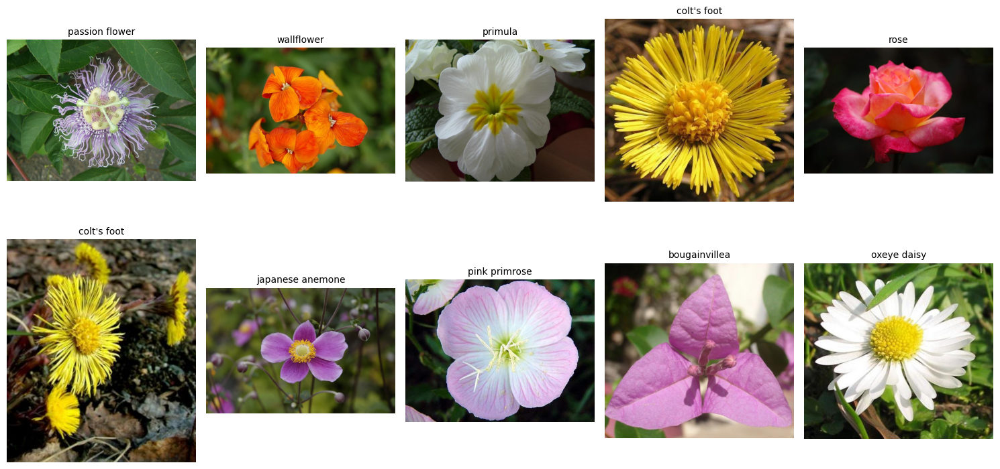

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 8))

indices = np.random.choice(len(images), 10, replace=False)

for i, index in enumerate(indices):

    filename = images[index]
    image_id = int(filename.split("_")[1].split(".")[0])

    img = Image.open(os.path.join(image_path, filename))
    label = class_mapping[int(labels[image_id - 1])]

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(label, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
import os
import shutil

dataset_path = "/content/flower_project/flower_dataset"

merge_mapping = {
    "rose": "roses",
    "sunflower": "sunflowers",
    "common dandelion": "dandelion",
    "oxeye daisy": "daisy",
    "barbeton daisy": "daisy"
}

In [17]:
for filename in images:

    image_id = int(filename.split("_")[1].split(".")[0])

    class_id = int(labels[image_id - 1])

    flower_name = class_mapping[class_id]

    flower_name = merge_mapping.get(flower_name, flower_name)

    folder_name = flower_name.replace(" ", "_")

    destination = os.path.join(dataset_path, folder_name)

    os.makedirs(destination, exist_ok=True)

    source = os.path.join(image_path, filename)

    target = os.path.join(destination, "oxford_" + filename)

    shutil.copy2(source, target)

print("Both datasets merged successfully!")

Both datasets merged successfully!


In [18]:
class_names = sorted([
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
])

total_images = 0

for name in class_names:

    folder = os.path.join(dataset_path, name)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    total_images += count

    print(f"{name}: {count}")

print("\nTotal flower categories:", len(class_names))
print("Total images:", total_images)

alpine_sea_holly: 43
anthurium: 105
artichoke: 78
azalea: 96
ball_moss: 46
balloon_flower: 49
bearded_iris: 54
bee_balm: 66
bird_of_paradise: 85
bishop_of_llandaff: 109
black-eyed_susan: 54
blackberry_lily: 48
blanket_flower: 49
bolero_deep_blue: 40
bougainvillea: 128
bromelia: 63
buttercup: 71
californian_poppy: 102
camellia: 91
canna_lily: 82
canterbury_bells: 40
cape_flower: 108
carnation: 52
cautleya_spicata: 50
clematis: 112
colt's_foot: 87
columbine: 86
corn_poppy: 41
cyclamen: 154
daffodil: 59
daisy: 809
dandelion: 990
desert-rose: 63
english_marigold: 65
fire_lily: 40
foxglove: 162
frangipani: 166
fritillary: 91
garden_phlox: 45
gaura: 67
gazania: 78
geranium: 114
giant_white_arum_lily: 56
globe-flower: 41
globe_thistle: 45
grape_hyacinth: 41
great_masterwort: 56
hard-leaved_pocket_orchid: 60
hibiscus: 131
hippeastrum: 76
japanese_anemone: 55
king_protea: 49
lenten_rose: 67
lotus: 137
love_in_the_mist: 46
magnolia: 63
mallow: 66
marigold: 67
mexican_aster: 40
mexican_petunia: 8

In [19]:
import os
from PIL import Image

dataset_path = "/content/flower_project/flower_dataset"

corrupted_images = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            path = os.path.join(root, file)

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    img.load()

            except Exception:
                corrupted_images.append(path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [20]:
import hashlib

seen = {}
duplicates = []
label_conflicts = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            path = os.path.join(root, file)

            with open(path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            if image_hash in seen:
                original = seen[image_hash]

                if os.path.dirname(original) == root:
                    duplicates.append(path)
                else:
                    label_conflicts.append((original, path))
            else:
                seen[image_hash] = path

print("Duplicate images:", len(duplicates))
print("Conflicting labels:", len(label_conflicts))

Duplicate images: 6
Conflicting labels: 1


In [21]:
remove_paths = set(corrupted_images + duplicates)

for path in remove_paths:
    if os.path.exists(path):
        os.remove(path)

print("Images removed:", len(remove_paths))

for original, duplicate in label_conflicts:
    print("Label conflict:", original, duplicate)

Images removed: 6
Label conflict: /content/flower_project/flower_dataset/roses/15922772266_1167a06620.jpg /content/flower_project/flower_dataset/tulips/15922772266_1167a06620.jpg


In [22]:
import numpy as np
import matplotlib.pyplot as plt

class_counts = {}

for name in sorted(os.listdir(dataset_path)):

    folder = os.path.join(dataset_path, name)

    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        class_counts[name] = count

print("Total classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))
print("Minimum images per class:", min(class_counts.values()))
print("Maximum images per class:", max(class_counts.values()))
print("Average images per class:", np.mean(list(class_counts.values())))

Total classes: 102
Total images: 11853
Minimum images per class: 40
Maximum images per class: 990
Average images per class: 116.20588235294117


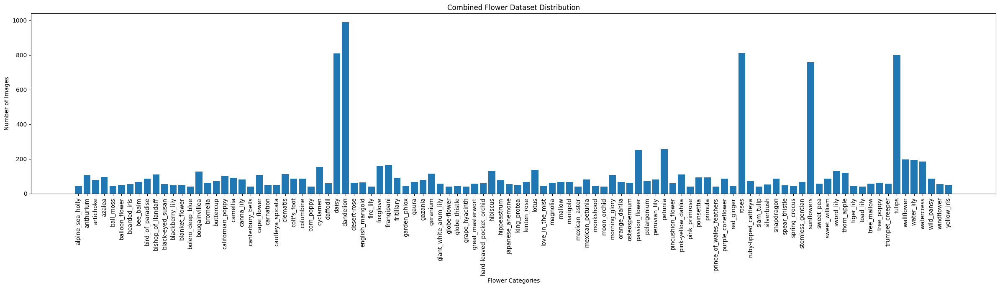

In [23]:
plt.figure(figsize=(24, 7))

plt.bar(class_counts.keys(), class_counts.values())

plt.xticks(rotation=90)
plt.xlabel("Flower Categories")
plt.ylabel("Number of Images")
plt.title("Combined Flower Dataset Distribution")
plt.tight_layout()
plt.show()

# 3. Image Loading and Preprocessing

Loading JPEG images, converting them into RGB arrays,
examining pixel values, resizing and normalization.

In [24]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random

In [25]:
dataset_path = "/content/flower_project/flower_dataset"

flower_class = random.choice(class_names)

folder_path = os.path.join(dataset_path, flower_class)

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_file = random.choice(image_files)

sample_path = os.path.join(folder_path, image_file)

print("Flower category:", flower_class)
print("Image path:", sample_path)

Flower category: daffodil
Image path: /content/flower_project/flower_dataset/daffodil/oxford_image_05741.jpg


Image shape: (500, 678, 3)
Data type: <dtype: 'uint8'>
Minimum pixel value: 0
Maximum pixel value: 255


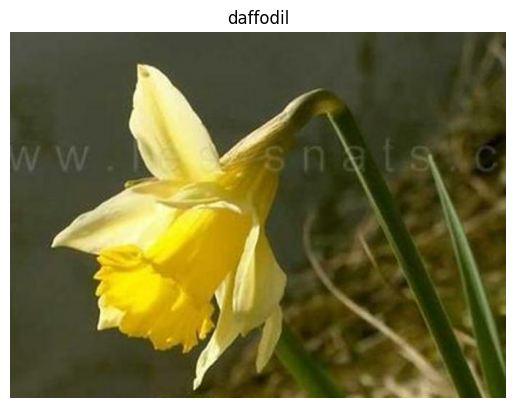

In [26]:
image = tf.io.read_file(sample_path)

image = tf.io.decode_image(
    image,
    channels=3,
    expand_animations=False
)

print("Image shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum pixel value:", tf.reduce_min(image).numpy())
print("Maximum pixel value:", tf.reduce_max(image).numpy())

plt.imshow(image.numpy())
plt.title(flower_class)
plt.axis("off")
plt.show()

In [27]:
print("First pixel RGB:", image[0, 0].numpy())

print("\nFirst 3 × 3 pixel values:")
print(image[:3, :3].numpy())

First pixel RGB: [83 85 72]

First 3 × 3 pixel values:
[[[83 85 72]
  [83 85 72]
  [83 85 72]]

 [[82 84 71]
  [82 84 71]
  [82 84 71]]

 [[82 84 71]
  [82 84 71]
  [82 84 71]]]


In [28]:
IMG_HEIGHT = 224
IMG_WIDTH = 224

resized_image = tf.image.resize(
    image,
    [IMG_HEIGHT, IMG_WIDTH]
)

print("Original shape:", image.shape)
print("Resized shape:", resized_image.shape)

Original shape: (500, 678, 3)
Resized shape: (224, 224, 3)


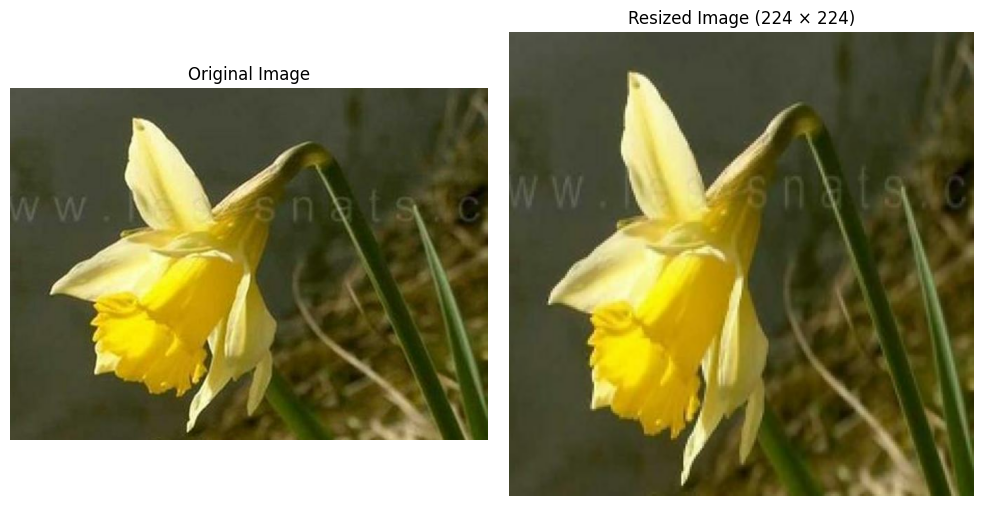

In [29]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.numpy())
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image.numpy().astype("uint8"))
plt.title("Resized Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3.2 Pixel Normalization

Scaling RGB pixel values from the range [0, 255]
to [0, 1] for stable neural network training.

Image shape: (224, 224, 3)
Data type: <dtype: 'float32'>
Minimum value: 0.0
Maximum value: 1.0


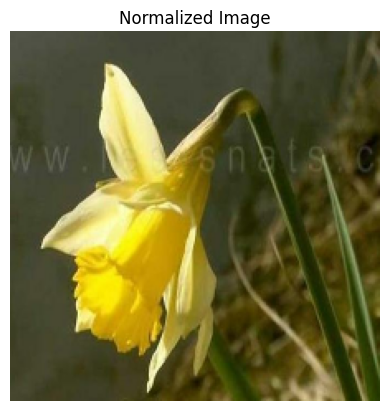

In [30]:
normalized_image = resized_image / 255.0

print("Image shape:", normalized_image.shape)
print("Data type:", normalized_image.dtype)

print("Minimum value:",
      tf.reduce_min(normalized_image).numpy())

print("Maximum value:",
      tf.reduce_max(normalized_image).numpy())

plt.imshow(normalized_image.numpy())
plt.title("Normalized Image")
plt.axis("off")
plt.show()

# 4. Dataset Splitting and Batch Processing

Creating stratified training, validation and testing datasets,
with automated image resizing, normalization and batching.

In [31]:
import tensorflow as tf
import numpy as np
import os

from sklearn.model_selection import train_test_split

dataset_path = "/content/flower_project/flower_dataset"

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

class_names = sorted([
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
])

NUM_CLASSES = len(class_names)

print("Image size:", (IMG_HEIGHT, IMG_WIDTH, 3))
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224, 3)
Batch size: 32
Number of classes: 102


## 4.2 Image Paths and Numerical Label Encoding

In [32]:
image_paths = []
image_labels = []

conflict_paths = {
    path
    for pair in label_conflicts
    for path in pair
}

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, class_name)

    for filename in sorted(os.listdir(folder)):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            path = os.path.join(folder, filename)

            if path not in conflict_paths:
                image_paths.append(path)
                image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total usable images:", len(image_paths))
print("Excluded conflicting paths:", len(conflict_paths))
print("Total labels:", len(image_labels))

print("\nFirst five class mappings:")

for i in range(5):
    print(i, ":", class_names[i])

Total usable images: 11851
Excluded conflicting paths: 2
Total labels: 11851

First five class mappings:
0 : alpine_sea_holly
1 : anthurium
2 : artichoke
3 : azalea
4 : ball_moss


## 4.3 Stratified Dataset Splitting (80:10:10)

In [33]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.2,
    random_state=SEED,
    stratify=image_labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 9480
Validation images: 1185
Testing images: 1186


## 4.4 Automated Image Decoding, Resizing and Normalization

In [34]:
def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = image / 255.0

    return image, label

## 4.5 TensorFlow Data Pipeline and Batch Processing

In [35]:
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=SEED
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels
)

test_ds = create_dataset(
    test_paths, test_labels
)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 297
Validation batches: 38
Testing batches: 38


In [36]:
for image_batch, label_batch in train_ds.take(1):

    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Data type:", image_batch.dtype)

    print("Minimum pixel value:",
          tf.reduce_min(image_batch).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(image_batch).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 4.7 Training Batch Visualization

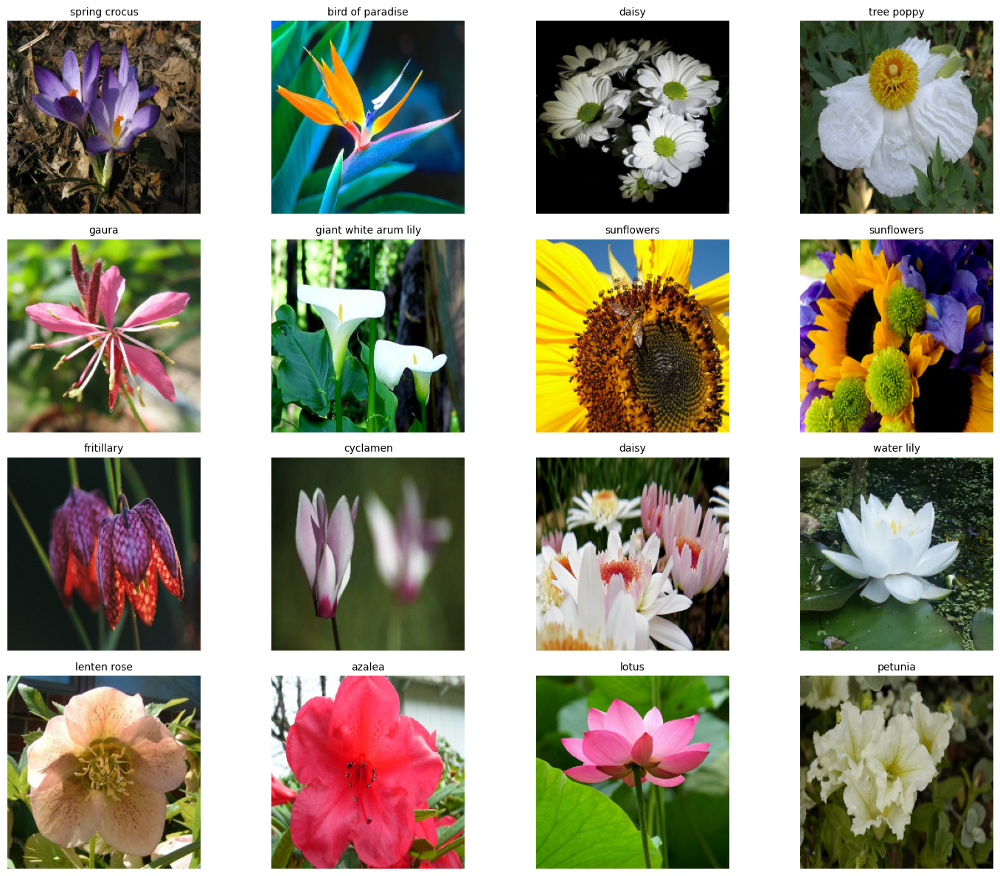

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 12))

for image_batch, label_batch in train_ds.take(1):

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(image_batch[i].numpy())

        label = int(label_batch[i].numpy())

        plt.title(
            class_names[label].replace("_", " "),
            fontsize=10
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

# 5. Linear Neural Network (LNN)

Implementation of a shallow linear neural network using
TensorFlow and Keras for multi-class flower classification.

## 5.1 Model Architecture

In [38]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Softmax

model = Sequential([
    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    Flatten(),
    Dense(NUM_CLASSES),
    Softmax()
], name="Flower_LNN")

model.summary()

Model: "Flower_LNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 102)            │    15,353,958 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 102)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,353,958 (58.57 MB)

 Trainable params: 15,353,958 (58.57 MB)

 Non-trainable params: 0 (0.00 B)

## 5.2 Trainable Parameters and Model Complexity

In [39]:
input_features = IMG_HEIGHT * IMG_WIDTH * 3

weights = input_features * NUM_CLASSES
biases = NUM_CLASSES

total_parameters = weights + biases

print("Input features:", input_features)
print("Weights:", weights)
print("Biases:", biases)
print("Total parameters:", total_parameters)
print("Model parameters:", model.count_params())

Input features: 150528
Weights: 15353856
Biases: 102
Total parameters: 15353958
Model parameters: 15353958


## 5.3 Softmax Activation Function

Converting raw classification scores into a probability
distribution across all flower categories.

In [40]:
sample_logits = tf.constant([2.0, 1.0, 4.0, 0.5, 1.5])

probabilities = tf.nn.softmax(sample_logits)

print("Raw scores:", sample_logits.numpy())
print("Probabilities:", probabilities.numpy())
print("Sum:", tf.reduce_sum(probabilities).numpy())

Raw scores: [2.  1.  4.  0.5 1.5]
Probabilities: [0.10431231 0.03837435 0.7707695  0.02327522 0.06326861]
Sum: 0.99999994


## 5.4 Model Compilation: Optimizer, Loss Function and Metrics

In [41]:
LEARNING_RATE = 0.001
EPOCHS = 15

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## 5.5 Forward Pass and Initial Prediction Verification

In [42]:
for image_batch, label_batch in train_ds.take(1):

    predictions = model(image_batch, training=False)

    print("Input shape:", image_batch.shape)
    print("Prediction shape:", predictions.shape)

    print("Actual label:", label_batch[0].numpy())

    predicted_label = tf.argmax(predictions[0]).numpy()

    print("Predicted label:", predicted_label)
    print("Predicted flower:", class_names[predicted_label])

    print("Probability sum:",
          tf.reduce_sum(predictions[0]).numpy())

Input shape: (32, 224, 224, 3)
Prediction shape: (32, 102)
Actual label: 39
Predicted label: 86
Predicted flower: sweet_pea
Probability sum: 0.99999994


# 6. Model Training and Performance Evaluation

Training the Linear Neural Network using the prepared
dataset and evaluating its classification performance.

## 6.1 Training the Baseline Model

In [43]:
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Number of classes:", NUM_CLASSES)
print("Epochs:", EPOCHS)

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 9480
Validation images: 1185
Number of classes: 102
Epochs: 15


In [44]:
import time

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

training_time = time.time() - start_time

print(f"\nTraining time: {training_time / 60:.2f} minutes")

Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 27s 84ms/step - accuracy: 0.0921 - loss: 65.6192 - val_accuracy: 0.0743 - val_loss: 42.5161
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - accuracy: 0.1718 - loss: 38.2032 - val_accuracy: 0.1013 - val_loss: 46.0383
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.2243 - loss: 34.5590 - val_accuracy: 0.1198 - val_loss: 43.1511
Epoch 4/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 34s 60ms/step - accuracy: 0.2774 - loss: 30.2748 - val_accuracy: 0.1173 - val_loss: 53.3548
Epoch 5/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.3131 - loss: 30.0399 - val_accuracy: 0.1190 - val_loss: 45.7070
Epoch 6/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.3653 - loss: 25.0751 - val_accuracy: 0.1207 - val_loss: 50.8457
Epoch 7/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.3619 - loss: 27.4854 - val_accuracy: 0.1435 - val_loss: 53.0178
Epoch 8/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.4019 - l

## 6.2 Training and Validation Accuracy Visualization

Analyzing classification accuracy across training epochs.

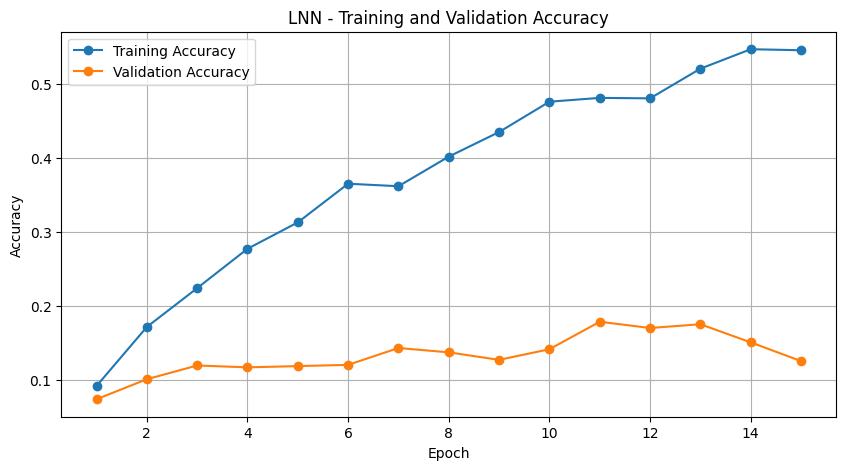

In [45]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LNN - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 6.3 Training and Validation Loss Visualization

Analyzing prediction error and identifying overfitting
or underfitting during model training.

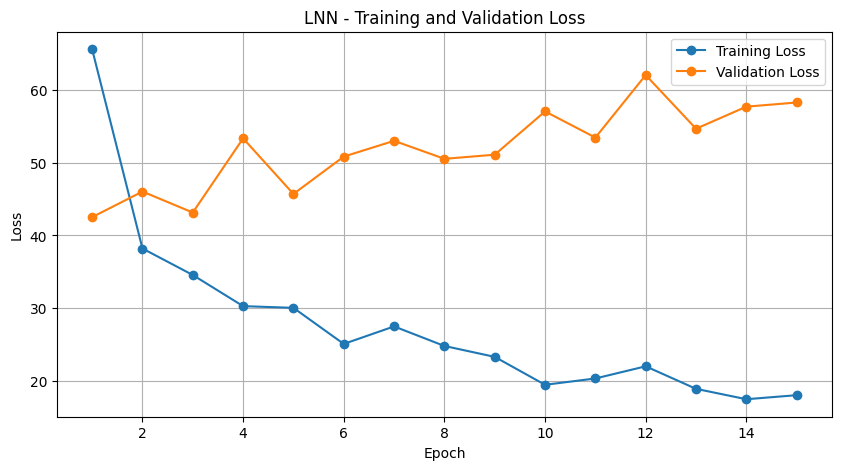

In [46]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LNN - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 6.4 Baseline Model Performance Summary

In [47]:
train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

best_val_accuracy = max(history.history["val_accuracy"])

best_epoch = np.argmax(
    history.history["val_accuracy"]
) + 1

print("===== LNN MODEL RESULTS =====")

print(f"Training Accuracy   : {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

print(f"Training Loss       : {train_loss:.4f}")
print(f"Validation Loss     : {val_loss:.4f}")

print(f"Best Val Accuracy   : {best_val_accuracy * 100:.2f}%")
print(f"Best Epoch          : {best_epoch}")

print(f"Training Time       : {training_time / 60:.2f} minutes")

print(f"Accuracy Gap        : {(train_accuracy - val_accuracy) * 100:.2f}%")

===== LNN MODEL RESULTS =====
Training Accuracy   : 54.56%
Validation Accuracy : 12.57%
Training Loss       : 18.0240
Validation Loss     : 58.2901
Best Val Accuracy   : 17.89%
Best Epoch          : 11
Training Time       : 5.56 minutes
Accuracy Gap        : 41.98%


## 6.5 Model Performance Benchmarking

Recording baseline model performance for comparison
with hyperparameter tuning, DNN, CNN and transfer learning.

In [48]:
import pandas as pd

results = []

results.append({
    "Model": "Baseline LNN",
    "Batch Size": BATCH_SIZE,
    "Learning Rate": LEARNING_RATE,
    "Epochs": EPOCHS,
    "Parameters": model.count_params(),
    "Training Accuracy (%)": train_accuracy * 100,
    "Validation Accuracy (%)": val_accuracy * 100,
    "Training Loss": train_loss,
    "Validation Loss": val_loss,
    "Training Time (min)": training_time / 60
})

results_df = pd.DataFrame(results)

display(results_df)

,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min)
0,Baseline LNN,32,0.001,15,15353958,54.55696,12.57384,18.024014,58.290131,5.563018


## 6.6 Baseline Model Saving

In [49]:
import os
import json

model_path = "/content/flower_project/models"

os.makedirs(model_path, exist_ok=True)

model.save(model_path + "/baseline_lnn.keras")

results_df.to_csv(
    model_path + "/model_results.csv",
    index=False
)

with open(model_path + "/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Baseline model saved successfully!")

Baseline model saved successfully!


# 7. Hyperparameter Tuning and Model Optimization

Experimenting with batch size, learning rate, epochs,
optimizers, loss functions and hidden layers to improve
flower classification performance.

## 7.1 Hyperparameter Configuration

In [50]:
experiments = [
    {
        "name": "LNN Experiment 1",
        "batch_size": 32,
        "learning_rate": 0.0001,
        "epochs": 15,
        "optimizer": "adam"
    },
    {
        "name": "LNN Experiment 2",
        "batch_size": 64,
        "learning_rate": 0.0001,
        "epochs": 15,
        "optimizer": "adam"
    },
    {
        "name": "LNN Experiment 3",
        "batch_size": 32,
        "learning_rate": 0.0005,
        "epochs": 15,
        "optimizer": "adam"
    },
    {
        "name": "LNN Experiment 4",
        "batch_size": 32,
        "learning_rate": 0.0001,
        "epochs": 15,
        "optimizer": "sgd"
    }
]

display(pd.DataFrame(experiments))

,name,batch_size,learning_rate,epochs,optimizer
0,LNN Experiment 1,32,0.0001,15,adam
1,LNN Experiment 2,64,0.0001,15,adam
2,LNN Experiment 3,32,0.0005,15,adam
3,LNN Experiment 4,32,0.0001,15,sgd


## 7.2 Dynamic Batch Size Configuration

In [51]:
def create_tuning_dataset(paths, labels, batch_size,
                          training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=SEED
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch_size)

    return dataset.prefetch(tf.data.AUTOTUNE)

## 7.3 Configurable Linear Neural Network Architecture

In [52]:
def build_lnn(learning_rate, optimizer_name):

    tuning_model = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(IMG_HEIGHT, IMG_WIDTH, 3)
        ),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(NUM_CLASSES),
        tf.keras.layers.Softmax()
    ])

    if optimizer_name == "adam":

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    elif optimizer_name == "sgd":

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    tuning_model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return tuning_model

## 7.4 Early Stopping and Overfitting Prevention

In [53]:
def get_callbacks():

    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
    ]

## 7.5 Automated Hyperparameter Tuning Experiments

Training multiple model configurations and recording
their validation accuracy, loss and execution time.

In [54]:
import time

tuning_results = []
tuning_histories = {}

best_tuned_accuracy = -1

for config in experiments:

    print("\n" + "=" * 60)
    print("Running:", config["name"])
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    tuned_train_ds = create_tuning_dataset(
        train_paths,
        train_labels,
        config["batch_size"],
        training=True
    )

    tuned_val_ds = create_tuning_dataset(
        val_paths,
        val_labels,
        config["batch_size"]
    )

    tuned_model = build_lnn(
        config["learning_rate"],
        config["optimizer"]
    )

    start = time.time()

    tuned_history = tuned_model.fit(
        tuned_train_ds,
        validation_data=tuned_val_ds,
        epochs=config["epochs"],
        callbacks=get_callbacks(),
        verbose=1
    )

    elapsed = (time.time() - start) / 60

    train_loss, train_acc = tuned_model.evaluate(
        tuned_train_ds, verbose=0
    )

    val_loss, val_acc = tuned_model.evaluate(
        tuned_val_ds, verbose=0
    )

    tuning_histories[config["name"]] = tuned_history.history

    tuning_results.append({
        "Model": config["name"],
        "Batch Size": config["batch_size"],
        "Learning Rate": config["learning_rate"],
        "Optimizer": config["optimizer"],
        "Epochs": len(tuned_history.history["loss"]),
        "Parameters": tuned_model.count_params(),
        "Training Accuracy (%)": train_acc * 100,
        "Validation Accuracy (%)": val_acc * 100,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Training Time (min)": elapsed
    })

    if val_acc > best_tuned_accuracy:

        best_tuned_accuracy = val_acc

        tuned_model.save(
            model_path + "/best_tuned_lnn.keras"
        )

        best_config = config.copy()

    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Training Time: {elapsed:.2f} minutes")

print("\nAll experiments completed!")


Running: LNN Experiment 1
Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - accuracy: 0.1254 - loss: 5.8862 - val_accuracy: 0.1300 - val_loss: 5.1505
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.2228 - loss: 4.4595 - val_accuracy: 0.1637 - val_loss: 5.5314
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - accuracy: 0.2991 - loss: 3.8256 - val_accuracy: 0.1662 - val_loss: 5.4930
Epoch 4/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.3642 - loss: 3.2821 - val_accuracy: 0.1688 - val_loss: 5.4021
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
Validation Accuracy: 13.00%
Training Time: 1.34 minutes

Running: LNN Experiment 2
Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.1322 - loss: 5.4040 - val_accuracy: 0.1350 - val_loss: 4.3120
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.2321 - loss: 3.6555 - val_accuracy: 0.1553 - val_loss: 4.4124
Epoch 3/15
149/149 ━━━━━━

## 7.6 Hyperparameter Performance Comparison

Comparing the baseline model and different hyperparameter
configurations to identify the best performing LNN.

In [60]:
print("Completed experiments:", len(tuning_results))

tuning_df = pd.DataFrame(tuning_results)

comparison_df = pd.concat(
    [results_df, tuning_df],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

Completed experiments: 4


,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min),Optimizer
0,LNN Experiment 4,32,0.0001,15,15353958,25.2743,19.1561,3.0348,3.2556,4.8045,sgd
1,LNN Experiment 3,32,0.0005,6,15353958,29.0190,13.5021,12.6287,20.1408,1.8733,adam
2,LNN Experiment 2,64,0.0001,4,15353958,19.0084,13.5021,3.6520,4.3120,1.2684,adam
3,LNN Experiment 1,32,0.0001,4,15353958,21.2342,12.9958,4.1415,5.1505,1.3424,adam
4,Baseline LNN,32,0.0010,15,15353958,54.5570,12.5738,18.0240,58.2901,5.5630,NaN


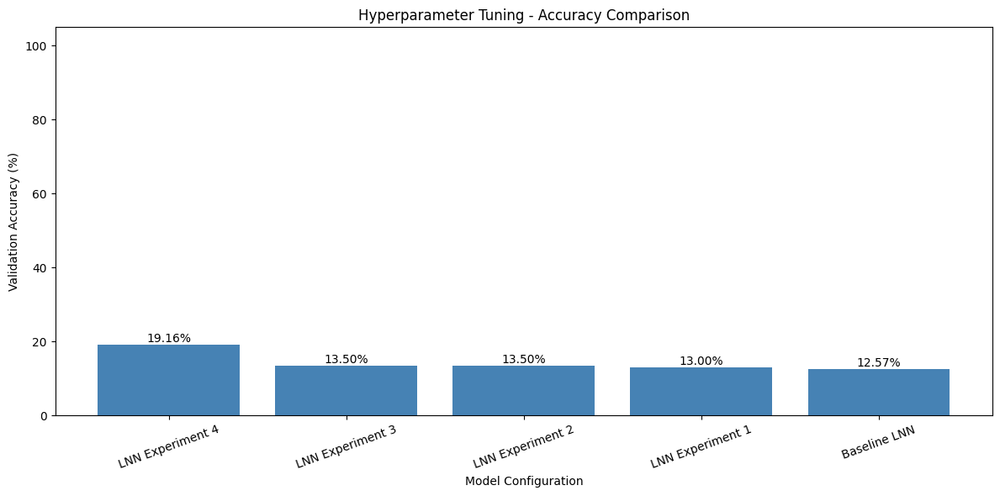

In [61]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Validation Accuracy (%)"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.2f%%")

plt.xlabel("Model Configuration")
plt.ylabel("Validation Accuracy (%)")
plt.title("Hyperparameter Tuning - Accuracy Comparison")

plt.xticks(rotation=20)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

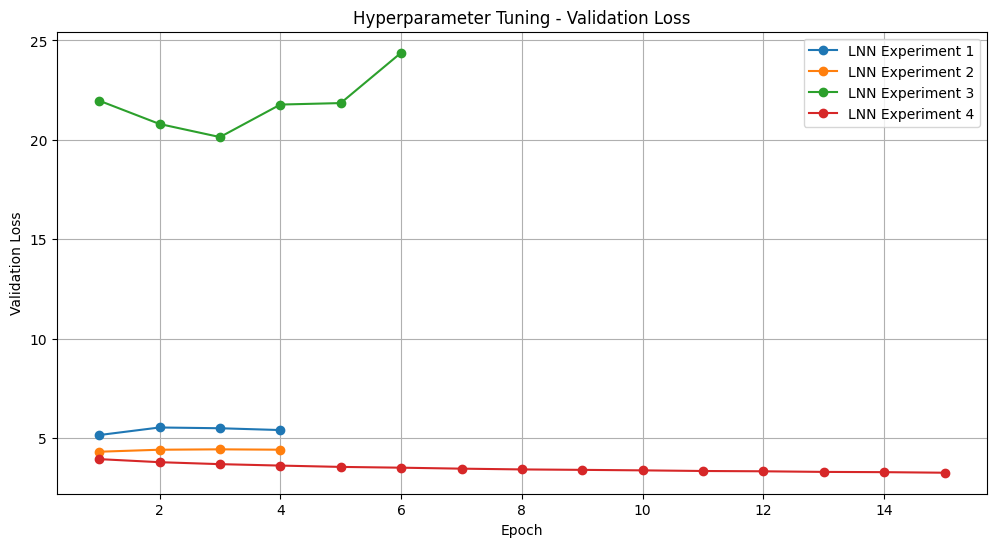

In [62]:
plt.figure(figsize=(12, 6))

for name, metrics in tuning_histories.items():

    plt.plot(
        range(1, len(metrics["val_loss"]) + 1),
        metrics["val_loss"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Hyperparameter Tuning - Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7.7 Best Hyperparameter Selection and Model Saving

Identifying the optimal hyperparameter configuration
based on validation accuracy and saving the best
Linear Neural Network for future comparison.

In [63]:
best_result = comparison_df.iloc[0]

print("===== BEST MODEL CONFIGURATION =====\n")
print(best_result.to_string())

baseline_accuracy = results_df.iloc[0][
    "Validation Accuracy (%)"
]

best_accuracy = best_result["Validation Accuracy (%)"]

improvement = best_accuracy - baseline_accuracy

print(f"\nBaseline Accuracy: {baseline_accuracy:.2f}%")
print(f"Best Accuracy: {best_accuracy:.2f}%")
print(f"Improvement: {improvement:.2f} percentage points")

===== BEST MODEL CONFIGURATION =====

Model                      LNN Experiment 4
Batch Size                               32
Learning Rate                        0.0001
Epochs                                   15
Parameters                         15353958
Training Accuracy (%)             25.274262
Validation Accuracy (%)           19.156118
Training Loss                       3.03483
Validation Loss                    3.255583
Training Time (min)                4.804513
Optimizer                               sgd

Baseline Accuracy: 12.57%
Best Accuracy: 19.16%
Improvement: 6.58 percentage points


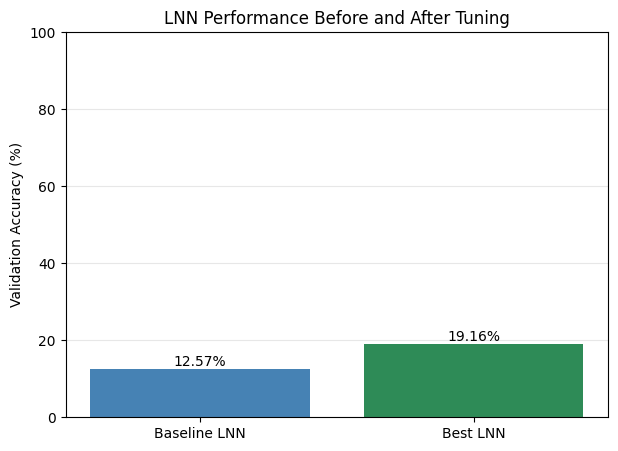

In [64]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Baseline LNN", "Best LNN"],
    [baseline_accuracy, best_accuracy],
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%")

plt.ylabel("Validation Accuracy (%)")
plt.title("LNN Performance Before and After Tuning")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [65]:
comparison_df.to_csv(
    model_path + "/hyperparameter_results.csv",
    index=False
)

if best_result["Model"] == "Baseline LNN":

    best_lnn = tf.keras.models.load_model(
        model_path + "/baseline_lnn.keras"
    )

else:

    best_lnn = tf.keras.models.load_model(
        model_path + "/best_tuned_lnn.keras"
    )

best_lnn.save(
    model_path + "/best_lnn.keras"
)

print("Best LNN saved successfully!")

Best LNN saved successfully!


In [66]:
best_lnn = tf.keras.models.load_model(
    model_path + "/best_lnn.keras"
)

lnn_val_loss, lnn_val_accuracy = best_lnn.evaluate(
    val_ds,
    verbose=1
)

print(f"Best LNN Accuracy: {lnn_val_accuracy * 100:.2f}%")
print(f"Best LNN Loss: {lnn_val_loss:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.1916 - loss: 3.2556
Best LNN Accuracy: 19.16%
Best LNN Loss: 3.2556


# 8. Deep Neural Network (DNN) Implementation

Improving flower classification using multiple hidden
layers, nonlinear activation functions, batch normalization
and dropout regularization.

## 8.1 DNN Architecture

In [67]:
from tensorflow.keras.layers import (
    Input,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    Softmax
)

tf.keras.utils.set_random_seed(SEED)

dnn_model = tf.keras.Sequential([
    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    Flatten(),

    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(NUM_CLASSES),
    Softmax()

], name="Flower_DNN")

dnn_model.summary()

Model: "Flower_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │    38,535,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 102)            │        13,158 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_1 (Softmax)             │ (None, 102)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,583,014 (147.18 MB)

 Trainable params: 38,582,246 (147.18 MB)

 Non-trainable params: 768 (3.00 KB)

## 8.2 ReLU Activation Function

Understanding nonlinear activation and its role
in learning complex image features.

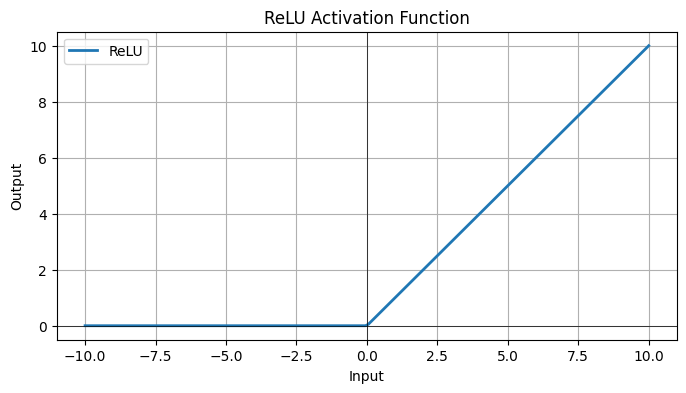

In [68]:
x = np.linspace(-10, 10, 200)

relu = tf.nn.relu(x).numpy()

plt.figure(figsize=(8, 4))

plt.plot(x, relu, label="ReLU", linewidth=2)

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("ReLU Activation Function")
plt.legend()
plt.grid(True)
plt.show()

## 8.3 Dropout Regularization and Batch Normalization

Reducing overfitting and improving the generalization
capability of the deep neural network.

## 8.4 DNN Model Compilation and Hyperparameter Configuration

In [69]:
DNN_LEARNING_RATE = 0.0001
DNN_EPOCHS = 20
DNN_BATCH_SIZE = 32

dnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=DNN_LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("DNN compiled successfully!")

DNN compiled successfully!


In [70]:
lnn_parameters = best_lnn.count_params()
dnn_parameters = dnn_model.count_params()

print(f"LNN Parameters: {lnn_parameters:,}")
print(f"DNN Parameters: {dnn_parameters:,}")

print(
    f"Parameter Ratio: "
    f"{dnn_parameters / lnn_parameters:.2f}x"
)

LNN Parameters: 15,353,958
DNN Parameters: 38,583,014
Parameter Ratio: 2.51x


## 8.6 Deep Neural Network Training

Training the nonlinear neural network using Adam optimizer,
early stopping and learning rate reduction to improve
classification performance and generalization.

In [71]:
dnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_path + "/best_dnn.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [72]:
import time

dnn_start_time = time.time()

dnn_history = dnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=DNN_EPOCHS,
    callbacks=dnn_callbacks,
    verbose=1
)

dnn_training_time = time.time() - dnn_start_time

print(
    f"\nDNN Training Time: "
    f"{dnn_training_time / 60:.2f} minutes"
)

Epoch 1/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.0526 - loss: 4.8001
Epoch 1: val_accuracy improved from None to 0.10211, saving model to /content/flower_project/models/best_dnn.keras

Epoch 1: finished saving model to /content/flower_project/models/best_dnn.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 49s 126ms/step - accuracy: 0.0766 - loss: 4.5556 - val_accuracy: 0.1021 - val_loss: 4.0990 - learning_rate: 1.0000e-04
Epoch 2/20
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.1244 - loss: 4.0735
Epoch 2: val_accuracy improved from 0.10211 to 0.12236, saving model to /content/flower_project/models/best_dnn.keras

Epoch 2: finished saving model to /content/flower_project/models/best_dnn.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - accuracy: 0.1296 - loss: 4.0457 - val_accuracy: 0.1224 - val_loss: 3.9700 - learning_rate: 1.0000e-04
Epoch 3/20
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1515 - loss: 3.8197
Epoch 3: val_accuracy improved from 0.12236 to 0.

## 8.7 DNN Accuracy and Loss Visualization

Visualizing training and validation performance
to identify learning patterns, overfitting and underfitting.

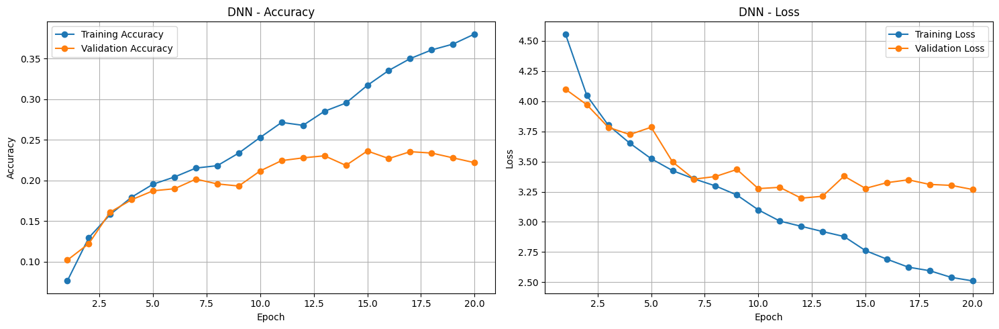

In [73]:
dnn_epochs_range = range(
    1, len(dnn_history.history["accuracy"]) + 1
)

plt.figure(figsize=(15, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    dnn_epochs_range,
    dnn_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    dnn_epochs_range,
    dnn_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DNN - Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    dnn_epochs_range,
    dnn_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    dnn_epochs_range,
    dnn_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN - Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 8.8 DNN Performance Evaluation

Evaluating the best saved DNN model and measuring
classification accuracy, loss and generalization gap.

In [74]:
best_dnn = tf.keras.models.load_model(
    model_path + "/best_dnn.keras"
)

dnn_train_loss, dnn_train_accuracy = best_dnn.evaluate(
    train_ds,
    verbose=0
)

dnn_val_loss, dnn_val_accuracy = best_dnn.evaluate(
    val_ds,
    verbose=0
)

dnn_best_epoch = np.argmax(
    dnn_history.history["val_accuracy"]
) + 1

print("===== DNN MODEL RESULTS =====\n")

print(f"Training Accuracy   : {dnn_train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {dnn_val_accuracy * 100:.2f}%")

print(f"Training Loss       : {dnn_train_loss:.4f}")
print(f"Validation Loss     : {dnn_val_loss:.4f}")

print(f"Best Epoch          : {dnn_best_epoch}")
print(f"Completed Epochs    : {len(dnn_history.history['loss'])}")

print(f"Training Time       : {dnn_training_time / 60:.2f} minutes")

print(
    f"Accuracy Gap        : "
    f"{(dnn_train_accuracy - dnn_val_accuracy) * 100:.2f}%"
)

===== DNN MODEL RESULTS =====

Training Accuracy   : 47.46%
Validation Accuracy : 23.63%
Training Loss       : 2.2674
Validation Loss     : 3.2775
Best Epoch          : 15
Completed Epochs    : 20
Training Time       : 8.28 minutes
Accuracy Gap        : 23.83%


## 8.9 Linear vs Deep Neural Network Performance Comparison

Comparing model complexity, classification accuracy,
validation loss and computational requirements.

In [75]:
lnn_dnn_df = pd.DataFrame([
    {
        "Model": "Best LNN",
        "Parameters": best_lnn.count_params(),
        "Validation Accuracy (%)": lnn_val_accuracy * 100,
        "Validation Loss": lnn_val_loss
    },
    {
        "Model": "DNN",
        "Parameters": best_dnn.count_params(),
        "Validation Accuracy (%)": dnn_val_accuracy * 100,
        "Validation Loss": dnn_val_loss
    }
])

display(lnn_dnn_df.round(4))

dnn_improvement = (
    dnn_val_accuracy - lnn_val_accuracy
) * 100

print(
    f"DNN Improvement: "
    f"{dnn_improvement:.2f} percentage points"
)

,Model,Parameters,Validation Accuracy (%),Validation Loss
0,Best LNN,15353958,19.1561,3.2556
1,DNN,38583014,23.6287,3.2775


DNN Improvement: 4.47 percentage points


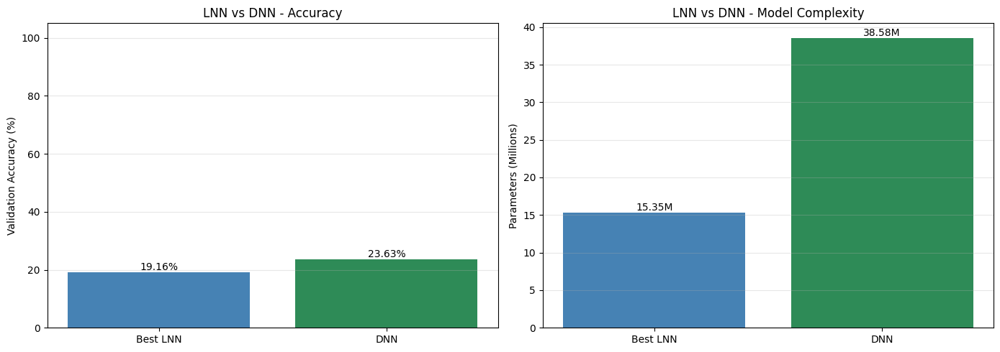

In [76]:
plt.figure(figsize=(14, 5))

# Accuracy comparison
plt.subplot(1, 2, 1)

bars = plt.bar(
    lnn_dnn_df["Model"],
    lnn_dnn_df["Validation Accuracy (%)"],
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Validation Accuracy (%)")
plt.title("LNN vs DNN - Accuracy")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

# Parameter comparison
plt.subplot(1, 2, 2)

bars = plt.bar(
    lnn_dnn_df["Model"],
    lnn_dnn_df["Parameters"] / 1000000,
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.2fM")
plt.ylabel("Parameters (Millions)")
plt.title("LNN vs DNN - Model Complexity")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 8.10 DNN Benchmark Recording and Model Saving

Maintaining a consolidated record of all model experiments
for final architecture selection and performance analysis.

In [77]:
dnn_result = {
    "Model": "DNN",
    "Batch Size": DNN_BATCH_SIZE,
    "Learning Rate": DNN_LEARNING_RATE,
    "Optimizer": "adam",
    "Epochs": len(dnn_history.history["loss"]),
    "Parameters": best_dnn.count_params(),
    "Training Accuracy (%)": dnn_train_accuracy * 100,
    "Validation Accuracy (%)": dnn_val_accuracy * 100,
    "Training Loss": dnn_train_loss,
    "Validation Loss": dnn_val_loss,
    "Training Time (min)": dnn_training_time / 60
}

all_results_df = pd.concat(
    [comparison_df, pd.DataFrame([dnn_result])],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

all_results_df.to_csv(
    model_path + "/all_model_results.csv",
    index=False
)

print("DNN benchmark results saved successfully!")

,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min),Optimizer
0,DNN,32,0.0001,20,38583014,47.4578,23.6287,2.2674,3.2775,8.2789,adam
1,LNN Experiment 4,32,0.0001,15,15353958,25.2743,19.1561,3.0348,3.2556,4.8045,sgd
2,LNN Experiment 3,32,0.0005,6,15353958,29.0190,13.5021,12.6287,20.1408,1.8733,adam
3,LNN Experiment 2,64,0.0001,4,15353958,19.0084,13.5021,3.6520,4.3120,1.2684,adam
4,LNN Experiment 1,32,0.0001,4,15353958,21.2342,12.9958,4.1415,5.1505,1.3424,adam
5,Baseline LNN,32,0.0010,15,15353958,54.5570,12.5738,18.0240,58.2901,5.5630,NaN


DNN benchmark results saved successfully!


# 9. Convolutional Neural Network (CNN) Implementation

Implementing convolutional layers, feature extraction,
max pooling, batch normalization and regularization
for improved flower image classification.

## 9.1 CNN Architecture and Feature Extraction

Proposed CNN architecture
Input image
224 × 224 × 3

Convolution Block 1
32 filters → 112 × 112 × 32

Convolution Block 2
64 filters → 56 × 56 × 64

Convolution Block 3
128 filters → 28 × 28 × 128

Convolution Block 4
256 filters → 14 × 14 × 256

Global Average Pooling
256 extracted features

Dense + ReLU + Dropout
128 neurons

Output + Softmax
102 flower categories (expected)

## 9.2 Convolution Operation and Feature Maps

Understanding how convolution filters extract local
features such as edges, textures and flower patterns.

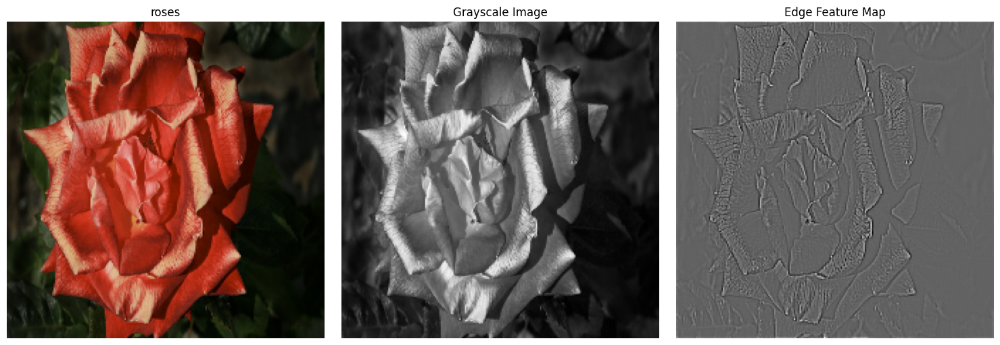

In [78]:
for images_batch, labels_batch in train_ds.take(1):
    cnn_sample = images_batch[0]
    cnn_sample_label = int(labels_batch[0].numpy())

gray_image = tf.image.rgb_to_grayscale(cnn_sample)

edge_kernel = tf.constant([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=tf.float32)

edge_kernel = tf.reshape(edge_kernel, [3, 3, 1, 1])

edge_image = tf.nn.conv2d(
    tf.expand_dims(gray_image, axis=0),
    edge_kernel,
    strides=1,
    padding="SAME"
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cnn_sample.numpy())
plt.title(class_names[cnn_sample_label])
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tf.squeeze(gray_image), cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tf.squeeze(edge_image), cmap="gray")
plt.title("Edge Feature Map")
plt.axis("off")

plt.tight_layout()
plt.show()

## 9.3 Max Pooling and Spatial Dimensionality Reduction

Reducing feature map dimensions while preserving
the strongest local feature activations.

In [79]:
sample_matrix = tf.constant([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 3],
    [1, 4, 2, 9]
], dtype=tf.float32)

pool_input = tf.reshape(sample_matrix, [1, 4, 4, 1])

pool_output = tf.nn.max_pool2d(
    pool_input,
    ksize=2,
    strides=2,
    padding="VALID"
)

print("Original Feature Map:")
print(sample_matrix.numpy())

print("\nAfter Max Pooling:")
print(tf.squeeze(pool_output).numpy())

Original Feature Map:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [1. 4. 2. 9.]]

After Max Pooling:
[[6. 4.]
 [7. 9.]]


## 9.4 CNN Model Architecture Implementation

Building a custom convolutional neural network with
four convolution blocks, global average pooling,
dense classification layers and dropout.

In [80]:
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Activation,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.models import Sequential

In [81]:
tf.keras.utils.set_random_seed(SEED)

cnn_model = Sequential([

    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Convolution Block 1
    Conv2D(32, (3, 3), padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 2
    Conv2D(64, (3, 3), padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 3
    Conv2D(128, (3, 3), padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 4
    Conv2D(256, (3, 3), padding="same"),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Classification Head
    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(NUM_CLASSES, activation="softmax")

], name="Flower_CNN")

cnn_model.summary()

Model: "Flower_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 436,390 (1.66 MB)

 Trainable params: 435,430 (1.66 MB)

 Non-trainable params: 960 (3.75 KB)

## 9.5 Global Average Pooling and Parameter Reduction

Reducing model complexity by averaging spatial
feature maps instead of flattening all feature values.

## 9.6 LNN, DNN and CNN Model Complexity Comparison

,Model,Parameters
0,LNN,15353958
1,DNN,38583014
2,CNN,436390


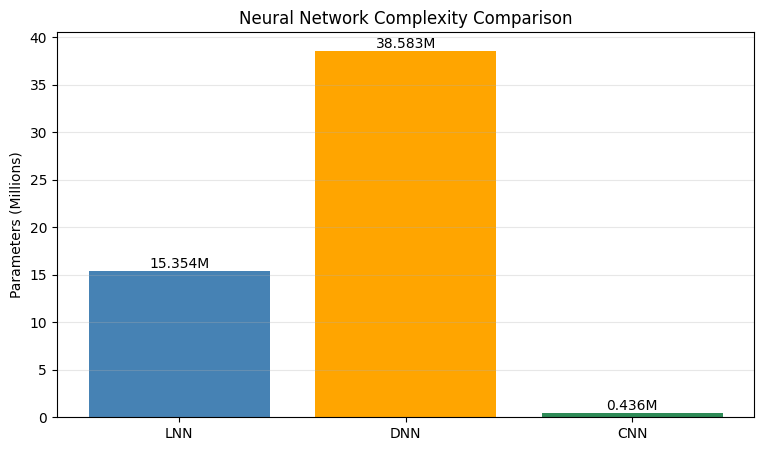

In [82]:
complexity_df = pd.DataFrame([
    {
        "Model": "LNN",
        "Parameters": best_lnn.count_params()
    },
    {
        "Model": "DNN",
        "Parameters": best_dnn.count_params()
    },
    {
        "Model": "CNN",
        "Parameters": cnn_model.count_params()
    }
])

display(complexity_df)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    complexity_df["Model"],
    complexity_df["Parameters"] / 1000000,
    color=["steelblue", "orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.3fM")

plt.ylabel("Parameters (Millions)")
plt.title("Neural Network Complexity Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 9.7 CNN Model Compilation and Hyperparameter Configuration

In [83]:
CNN_LEARNING_RATE = 0.001
CNN_BATCH_SIZE = 32
CNN_EPOCHS = 30

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=CNN_LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")

CNN compiled successfully!


## 9.8 CNN Forward Pass and Output Verification

In [84]:
for image_batch, label_batch in train_ds.take(1):

    cnn_predictions = cnn_model(
        image_batch,
        training=False
    )

    print("Input shape:", image_batch.shape)
    print("Output shape:", cnn_predictions.shape)

    print(
        "Probability sum:",
        tf.reduce_sum(cnn_predictions[0]).numpy()
    )

    predicted_class = tf.argmax(
        cnn_predictions[0]
    ).numpy()

    print("Predicted flower:", class_names[predicted_class])
    print("Actual flower:", class_names[int(label_batch[0])])

Input shape: (32, 224, 224, 3)
Output shape: (32, 102)
Probability sum: 1.0
Predicted flower: morning_glory
Actual flower: red_ginger


## 9.9 CNN Model Training

Training the custom convolutional neural network
using early stopping, adaptive learning rate reduction
and model checkpointing.

In [85]:
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_path + "/best_cnn.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [86]:
import time

cnn_start_time = time.time()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=cnn_callbacks,
    verbose=1
)

cnn_training_time = time.time() - cnn_start_time

print(
    f"\nCNN Training Time: "
    f"{cnn_training_time / 60:.2f} minutes"
)

Epoch 1/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.1434 - loss: 3.8902
Epoch 1: val_accuracy improved from None to 0.11224, saving model to /content/flower_project/models/best_cnn.keras

Epoch 1: finished saving model to /content/flower_project/models/best_cnn.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 79s 196ms/step - accuracy: 0.1773 - loss: 3.5972 - val_accuracy: 0.1122 - val_loss: 4.0120 - learning_rate: 0.0010
Epoch 2/30
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.2201 - loss: 3.1447
Epoch 2: val_accuracy improved from 0.11224 to 0.20506, saving model to /content/flower_project/models/best_cnn.keras

Epoch 2: finished saving model to /content/flower_project/models/best_cnn.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 26s 86ms/step - accuracy: 0.2284 - loss: 3.0863 - val_accuracy: 0.2051 - val_loss: 3.3590 - learning_rate: 0.0010
Epoch 3/30
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.2663 - loss: 2.8908
Epoch 3: val_accuracy improved from 0.20506 to 0.27089, 

## 9.10 CNN Training and Validation Performance

Visualizing accuracy and loss across training epochs
to analyze convergence and generalization.

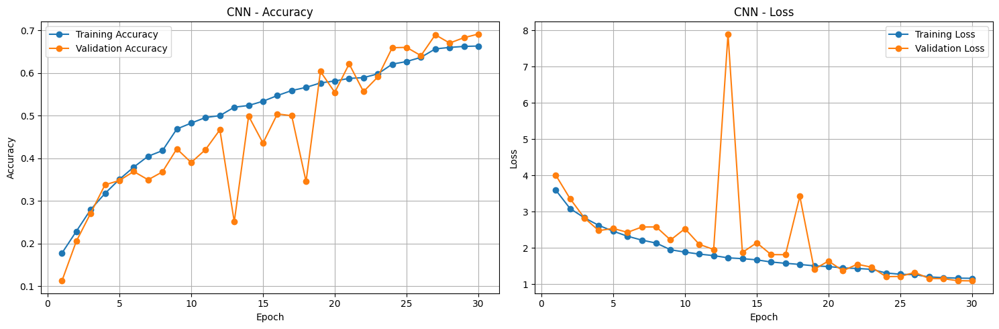

In [87]:
cnn_epochs_range = range(
    1, len(cnn_history.history["accuracy"]) + 1
)

plt.figure(figsize=(15, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    cnn_epochs_range,
    cnn_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    cnn_epochs_range,
    cnn_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN - Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    cnn_epochs_range,
    cnn_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    cnn_epochs_range,
    cnn_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN - Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 9.11 CNN Performance Evaluation

Evaluating the best saved CNN model using training
and validation accuracy, loss and generalization gap.

In [88]:
best_cnn = tf.keras.models.load_model(
    model_path + "/best_cnn.keras"
)

cnn_train_loss, cnn_train_accuracy = best_cnn.evaluate(
    train_ds,
    verbose=0
)

cnn_val_loss, cnn_val_accuracy = best_cnn.evaluate(
    val_ds,
    verbose=0
)

cnn_best_epoch = np.argmax(
    cnn_history.history["val_accuracy"]
) + 1

print("===== CNN MODEL RESULTS =====\n")

print(f"Training Accuracy   : {cnn_train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {cnn_val_accuracy * 100:.2f}%")

print(f"Training Loss       : {cnn_train_loss:.4f}")
print(f"Validation Loss     : {cnn_val_loss:.4f}")

print(f"Best Epoch          : {cnn_best_epoch}")
print(f"Completed Epochs    : {len(cnn_history.history['loss'])}")

print(f"Total Parameters    : {best_cnn.count_params():,}")
print(f"Training Time       : {cnn_training_time / 60:.2f} min")

print(
    f"Accuracy Gap        : "
    f"{(cnn_train_accuracy - cnn_val_accuracy) * 100:.2f}%"
)

===== CNN MODEL RESULTS =====

Training Accuracy   : 77.16%
Validation Accuracy : 69.11%
Training Loss       : 0.7997
Validation Loss     : 1.0890
Best Epoch          : 30
Completed Epochs    : 30
Total Parameters    : 436,390
Training Time       : 16.10 min
Accuracy Gap        : 8.05%


## 9.12 Neural Network Architecture Performance Comparison

Comparing linear, deep and convolutional neural networks
based on validation accuracy, loss and model complexity.

In [89]:
architecture_df = pd.DataFrame([
    {
        "Model": "Best LNN",
        "Parameters": best_lnn.count_params(),
        "Validation Accuracy (%)": lnn_val_accuracy * 100,
        "Validation Loss": lnn_val_loss
    },
    {
        "Model": "DNN",
        "Parameters": best_dnn.count_params(),
        "Validation Accuracy (%)": dnn_val_accuracy * 100,
        "Validation Loss": dnn_val_loss
    },
    {
        "Model": "CNN",
        "Parameters": best_cnn.count_params(),
        "Validation Accuracy (%)": cnn_val_accuracy * 100,
        "Validation Loss": cnn_val_loss
    }
])

display(architecture_df.round(4))

,Model,Parameters,Validation Accuracy (%),Validation Loss
0,Best LNN,15353958,19.1561,3.2556
1,DNN,38583014,23.6287,3.2775
2,CNN,436390,69.1139,1.0890


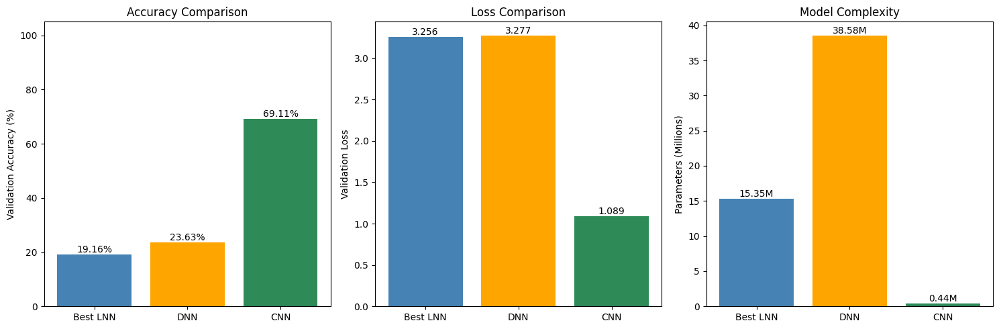

In [90]:
plt.figure(figsize=(15, 5))

# Accuracy comparison
plt.subplot(1, 3, 1)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Validation Accuracy (%)"],
    color=["steelblue", "orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Validation Accuracy (%)")
plt.title("Accuracy Comparison")
plt.ylim(0, 105)

# Loss comparison
plt.subplot(1, 3, 2)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Validation Loss"],
    color=["steelblue", "orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.3f")
plt.ylabel("Validation Loss")
plt.title("Loss Comparison")

# Parameter comparison
plt.subplot(1, 3, 3)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Parameters"] / 1000000,
    color=["steelblue", "orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.2fM")
plt.ylabel("Parameters (Millions)")
plt.title("Model Complexity")

plt.tight_layout()
plt.show()

## 9.13 CNN Benchmark Recording and Model Saving

Recording CNN performance for final comparison
with pretrained and fine-tuned models.

In [91]:
cnn_result = {
    "Model": "CNN",
    "Batch Size": CNN_BATCH_SIZE,
    "Learning Rate": CNN_LEARNING_RATE,
    "Optimizer": "adam",
    "Epochs": len(cnn_history.history["loss"]),
    "Parameters": best_cnn.count_params(),
    "Training Accuracy (%)": cnn_train_accuracy * 100,
    "Validation Accuracy (%)": cnn_val_accuracy * 100,
    "Training Loss": cnn_train_loss,
    "Validation Loss": cnn_val_loss,
    "Training Time (min)": cnn_training_time / 60
}

all_results_df = all_results_df[
    all_results_df["Model"] != "CNN"
]

all_results_df = pd.concat(
    [all_results_df, pd.DataFrame([cnn_result])],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

all_results_df.to_csv(
    model_path + "/all_model_results.csv",
    index=False
)

print("CNN benchmark saved successfully!")

,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min),Optimizer
0,CNN,32,0.0010,30,436390,77.1624,69.1139,0.7997,1.0890,16.0996,adam
1,DNN,32,0.0001,20,38583014,47.4578,23.6287,2.2674,3.2775,8.2789,adam
2,LNN Experiment 4,32,0.0001,15,15353958,25.2743,19.1561,3.0348,3.2556,4.8045,sgd
3,LNN Experiment 3,32,0.0005,6,15353958,29.0190,13.5021,12.6287,20.1408,1.8733,adam
4,LNN Experiment 2,64,0.0001,4,15353958,19.0084,13.5021,3.6520,4.3120,1.2684,adam
5,LNN Experiment 1,32,0.0001,4,15353958,21.2342,12.9958,4.1415,5.1505,1.3424,adam
6,Baseline LNN,32,0.0010,15,15353958,54.5570,12.5738,18.0240,58.2901,5.5630,NaN


CNN benchmark saved successfully!


# 10. Data Augmentation

Improving model generalization by applying random image
transformations to increase training data diversity
and reduce overfitting.

## 10.1 Data Augmentation Pipeline

In [92]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.15),

    layers.RandomTranslation(0.1, 0.1),

    layers.RandomContrast(0.15)

], name="Data_Augmentation")

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


## 10.2 Data Augmentation Visualization

Visualizing multiple randomly transformed versions
of a single flower image.

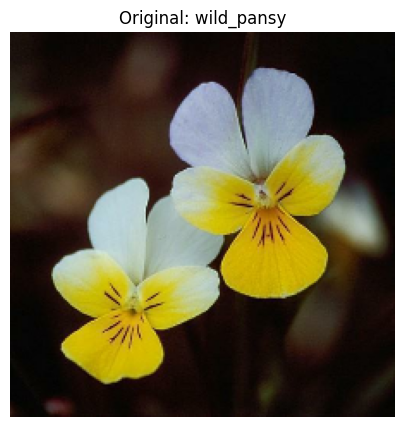

In [93]:
for images, labels in train_ds.take(1):

    aug_sample = images[0]
    aug_label = int(labels[0].numpy())

plt.figure(figsize=(5, 5))

plt.imshow(aug_sample.numpy())
plt.title("Original: " + class_names[aug_label])
plt.axis("off")
plt.show()

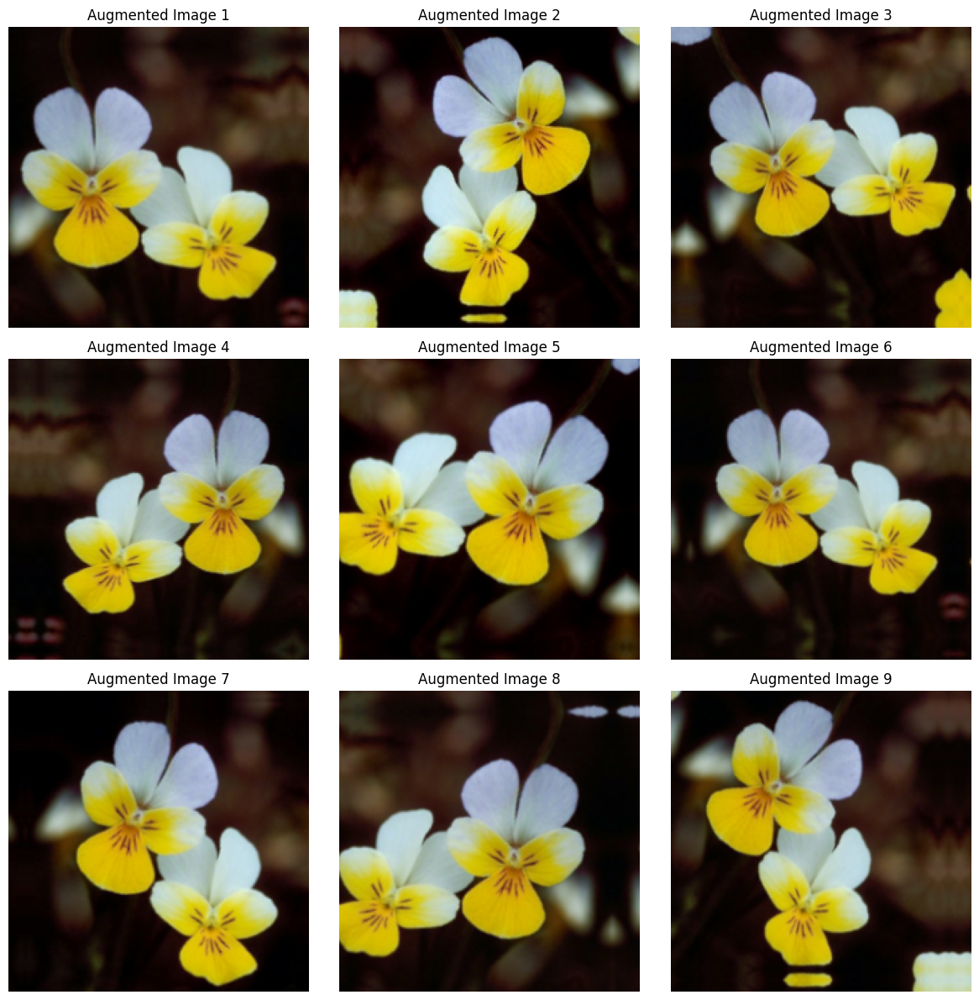

In [94]:
plt.figure(figsize=(12, 12))

for i in range(9):

    augmented_image = data_augmentation(
        tf.expand_dims(aug_sample, axis=0),
        training=True
    )

    augmented_image = tf.clip_by_value(
        augmented_image, 0.0, 1.0
    )

    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_image[0].numpy())

    plt.title(f"Augmented Image {i + 1}")

    plt.axis("off")

plt.tight_layout()
plt.show()

## 10.3 Individual Image Transformation Analysis

Analyzing the effects of flipping, rotation, zoom,
translation and contrast adjustments individually.

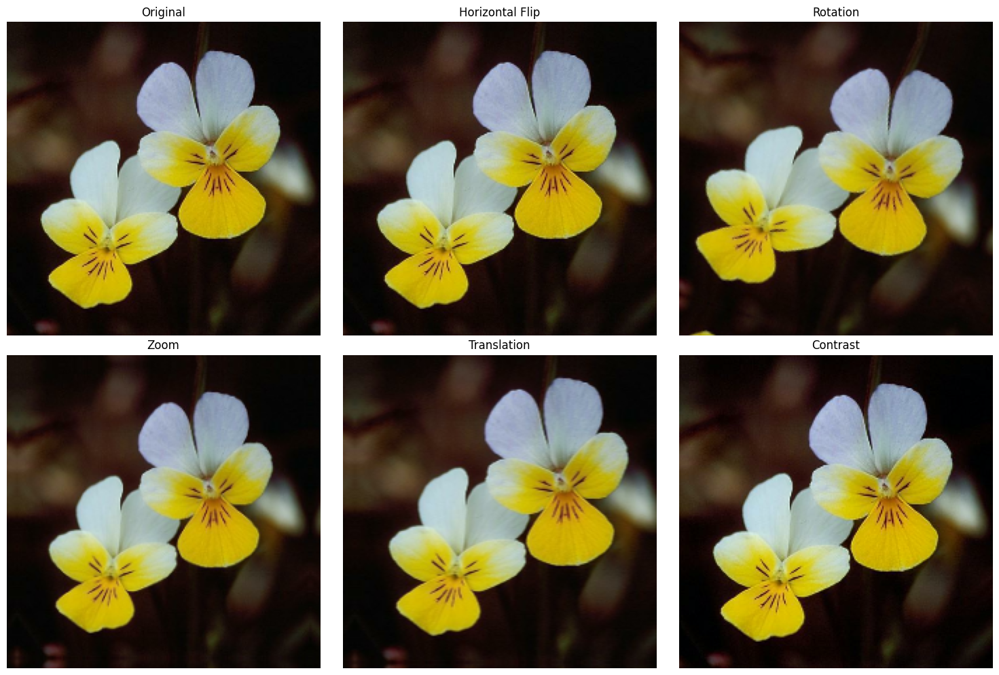

In [95]:
transformations = [
    ("Original", None),
    ("Horizontal Flip", layers.RandomFlip("horizontal")),
    ("Rotation", layers.RandomRotation(0.1)),
    ("Zoom", layers.RandomZoom(0.15)),
    ("Translation", layers.RandomTranslation(0.1, 0.1)),
    ("Contrast", layers.RandomContrast(0.15))
]

plt.figure(figsize=(15, 10))

for i, (name, transform) in enumerate(transformations):

    img = tf.expand_dims(aug_sample, axis=0)

    if transform is not None:
        img = transform(img, training=True)

    img = tf.clip_by_value(img, 0.0, 1.0)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img[0].numpy())
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 10.4 Training Pipeline Integration

Applying random augmentation exclusively during training
while preserving the original validation and testing data.

In [96]:
sample_batch = tf.expand_dims(aug_sample, axis=0)

augmented_output = data_augmentation(
    sample_batch,
    training=True
)

original_output = data_augmentation(
    sample_batch,
    training=False
)

print("Original shape:", sample_batch.shape)
print("Augmented shape:", augmented_output.shape)

print(
    "Unchanged during inference:",
    np.allclose(
        sample_batch.numpy(),
        original_output.numpy()
    )
)

Original shape: (1, 224, 224, 3)
Augmented shape: (1, 224, 224, 3)
Unchanged during inference: True


# 11. Pretrained MobileNetV2 and Transfer Learning

Leveraging pretrained ImageNet weights to improve flower
classification accuracy using transfer learning,
feature extraction and fine-tuning.

## 11.1 Pretrained Model Architecture

## 11.3 Loading Pretrained MobileNetV2

Loading ImageNet weights and removing the original
classification layer to use MobileNetV2 as a
feature extraction network.

In [97]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(SEED)

base_model = MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully!")

print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)
print("Total parameters:", base_model.count_params())
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 1280)
Total parameters: 2257984
Total layers: 154


## 11.4 Freezing Pretrained Layers

Preserving previously learned ImageNet features
by preventing pretrained weight updates during
initial transfer learning.

In [98]:
base_model.trainable = False

print("Base model trainable:", base_model.trainable)

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

print(
    "Frozen layers:",
    sum(not layer.trainable for layer in base_model.layers)
)

Base model trainable: False
Trainable layers: 0
Frozen layers: 154


## 11.5 MobileNetV2 Input Preprocessing

Converting normalized RGB pixel values from the
range [0, 1] into the pretrained model's expected
range [-1, 1].

In [99]:
mobilenet_preprocessing = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)

for images, labels in train_ds.take(1):

    processed_images = mobilenet_preprocessing(images)

    print("Before preprocessing:")

    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())

    print("\nAfter preprocessing:")

    print("Minimum:", tf.reduce_min(processed_images).numpy())
    print("Maximum:", tf.reduce_max(processed_images).numpy())

Before preprocessing:
Minimum: 0.0
Maximum: 1.0

After preprocessing:
Minimum: -1.0
Maximum: 1.0


## 11.6 Pretrained Feature Extraction and Visualization

Extracting and visualizing spatial feature maps
generated by the pretrained MobileNetV2 network.

Original image shape: (224, 224, 3)
Extracted feature shape: (1, 7, 7, 1280)


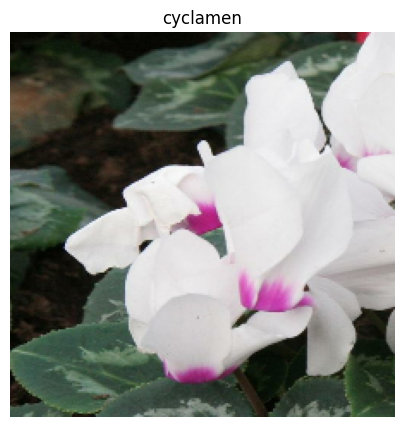

In [100]:
for images, labels in train_ds.take(1):

    feature_sample = images[0]
    feature_label = int(labels[0].numpy())

sample_input = tf.expand_dims(
    feature_sample,
    axis=0
)

sample_input = mobilenet_preprocessing(sample_input)

feature_maps = base_model(
    sample_input,
    training=False
)

print("Original image shape:", feature_sample.shape)
print("Extracted feature shape:", feature_maps.shape)

plt.figure(figsize=(5, 5))

plt.imshow(feature_sample.numpy())
plt.title(class_names[feature_label])
plt.axis("off")
plt.show()

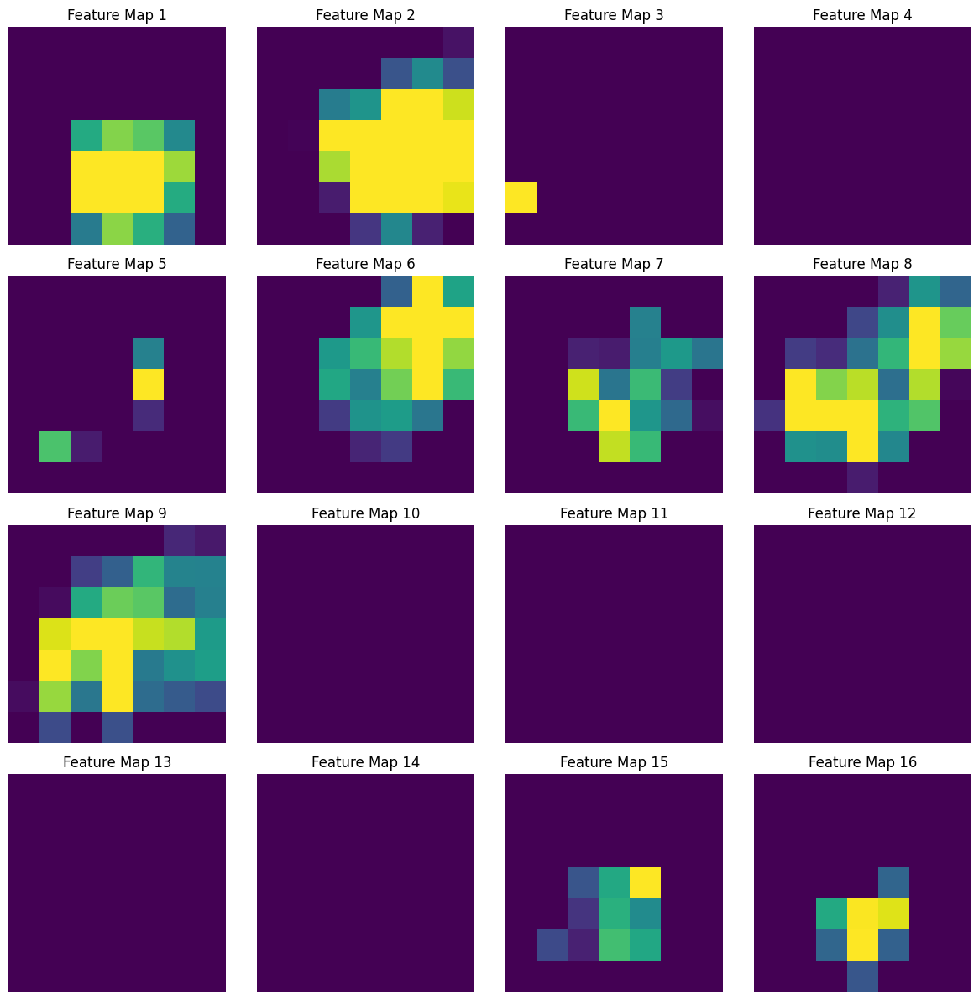

In [101]:
plt.figure(figsize=(12, 12))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        feature_maps[0, :, :, i],
        cmap="viridis"
    )

    plt.title(f"Feature Map {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 11.7 Transfer Learning Model Implementation

Combining data augmentation, input preprocessing,
pretrained feature extraction and a custom
flower classification head.

In [102]:
inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Data augmentation
x = data_augmentation(inputs)

# Keep augmented pixels within the expected range
x = layers.ReLU(max_value=1.0)(x)

# MobileNetV2 preprocessing
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x)

# Pretrained feature extraction
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transfer_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Flower_MobileNetV2"
)

transfer_model.summary()

Model: "Flower_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_Augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 102)            │        26,214 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,612,134 (9.96 MB)

 Trainable params: 354,150 (1.35 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11.8 Trainable and Non-Trainable Parameter Analysis

Analyzing the computational benefits of freezing
pretrained feature extraction layers.

Total Parameters: 2,612,134
Trainable Parameters: 354,150
Frozen Parameters: 2,257,984
Trainable Percentage: 13.56%


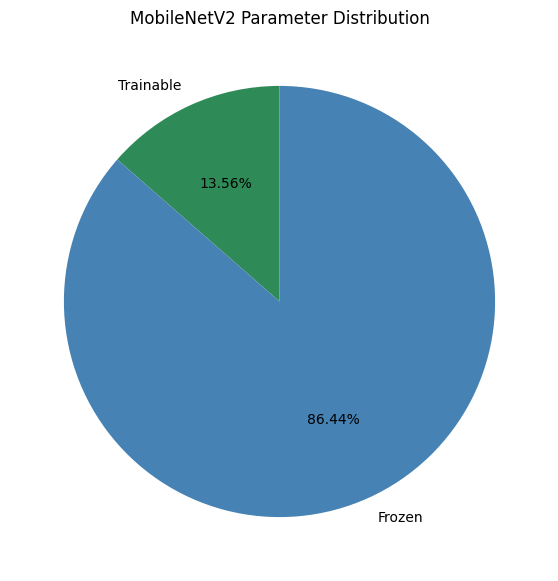

In [103]:
trainable_params = sum(
    int(np.prod(w.shape))
    for w in transfer_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in transfer_model.non_trainable_weights
)

total_params = transfer_model.count_params()

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters: {frozen_params:,}")

print(
    f"Trainable Percentage: "
    f"{trainable_params / total_params * 100:.2f}%"
)

plt.figure(figsize=(7, 7))

plt.pie(
    [trainable_params, frozen_params],
    labels=["Trainable", "Frozen"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["seagreen", "steelblue"]
)

plt.title("MobileNetV2 Parameter Distribution")
plt.show()

## 11.9 Transfer Learning Model Compilation
and Hyperparameter Configuration

In [104]:
TRANSFER_LEARNING_RATE = 0.001
TRANSFER_EPOCHS = 15
TRANSFER_BATCH_SIZE = 32

transfer_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TRANSFER_LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Transfer learning model compiled successfully!")

Transfer learning model compiled successfully!


In [105]:
for images, labels in train_ds.take(1):

    transfer_predictions = transfer_model(
        images,
        training=False
    )

    print("Input shape:", images.shape)

    print("Output shape:", transfer_predictions.shape)

    print(
        "Probability sum:",
        tf.reduce_sum(transfer_predictions[0]).numpy()
    )

    predicted_index = int(
        tf.argmax(transfer_predictions[0]).numpy()
    )

    print("Predicted flower:", class_names[predicted_index])

    print("Actual flower:", class_names[int(labels[0])])

Input shape: (32, 224, 224, 3)
Output shape: (32, 102)
Probability sum: 1.0
Predicted flower: lenten_rose
Actual flower: foxglove


## 11.11 Transfer Learning Model Training

Training the custom classification head while preserving
pretrained ImageNet feature extraction weights using
early stopping and adaptive learning rate reduction.

In [106]:
transfer_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_path + "/best_transfer.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [107]:
import time

transfer_start_time = time.time()

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRANSFER_EPOCHS,
    callbacks=transfer_callbacks,
    verbose=1
)

transfer_training_time = time.time() - transfer_start_time

print(
    f"\nTransfer Learning Training Time: "
    f"{transfer_training_time / 60:.2f} minutes"
)

Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.3490 - loss: 2.9861
Epoch 1: val_accuracy improved from None to 0.70970, saving model to /content/flower_project/models/best_transfer.keras

Epoch 1: finished saving model to /content/flower_project/models/best_transfer.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 39s 100ms/step - accuracy: 0.4746 - loss: 2.2243 - val_accuracy: 0.7097 - val_loss: 1.0946 - learning_rate: 0.0010
Epoch 2/15
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.6906 - loss: 1.1217
Epoch 2: val_accuracy improved from 0.70970 to 0.81519, saving model to /content/flower_project/models/best_transfer.keras

Epoch 2: finished saving model to /content/flower_project/models/best_transfer.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 35s 116ms/step - accuracy: 0.7068 - loss: 1.0529 - val_accuracy: 0.8152 - val_loss: 0.7301 - learning_rate: 0.0010
Epoch 3/15
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7718 - loss: 0.8151
Epoch 3: val_accuracy did not impro

## 11.12 Transfer Learning Accuracy and Loss Visualization

Analyzing the learning performance and generalization
capability of the pretrained MobileNetV2 model.

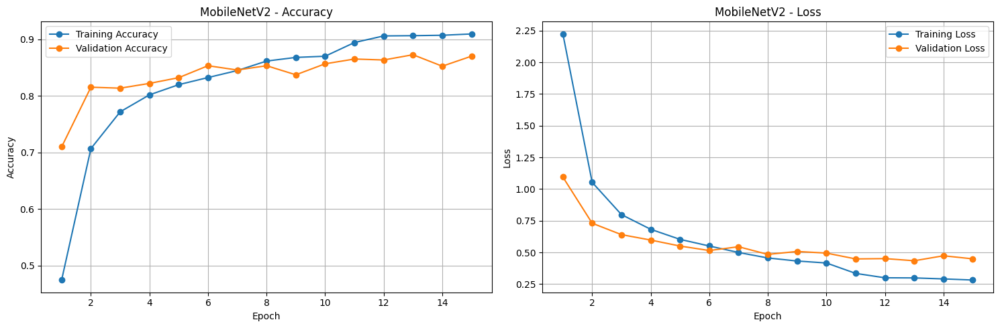

In [108]:
transfer_epochs_range = range(
    1, len(transfer_history.history["accuracy"]) + 1
)

plt.figure(figsize=(15, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    transfer_epochs_range,
    transfer_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    transfer_epochs_range,
    transfer_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 - Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    transfer_epochs_range,
    transfer_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    transfer_epochs_range,
    transfer_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 - Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11.13 Transfer Learning Performance Evaluation

Evaluating the best pretrained model checkpoint
using classification accuracy, loss, training time
and model complexity.

In [109]:
best_transfer = tf.keras.models.load_model(
    model_path + "/best_transfer.keras"
)

transfer_train_loss, transfer_train_accuracy = (
    best_transfer.evaluate(train_ds, verbose=0)
)

transfer_val_loss, transfer_val_accuracy = (
    best_transfer.evaluate(val_ds, verbose=0)
)

transfer_best_epoch = np.argmax(
    transfer_history.history["val_accuracy"]
) + 1

print("===== TRANSFER LEARNING RESULTS =====\n")

print(f"Training Accuracy   : {transfer_train_accuracy * 100:.2f}%")

print(f"Validation Accuracy : {transfer_val_accuracy * 100:.2f}%")

print(f"Training Loss       : {transfer_train_loss:.4f}")

print(f"Validation Loss     : {transfer_val_loss:.4f}")

print(f"Best Epoch          : {transfer_best_epoch}")

print(f"Completed Epochs    : {len(transfer_history.history['loss'])}")

print(f"Total Parameters    : {best_transfer.count_params():,}")

print(f"Training Time       : {transfer_training_time / 60:.2f} min")

===== TRANSFER LEARNING RESULTS =====

Training Accuracy   : 94.44%
Validation Accuracy : 87.26%
Training Loss       : 0.1905
Validation Loss     : 0.4339
Best Epoch          : 13
Completed Epochs    : 15
Total Parameters    : 2,612,134
Training Time       : 7.80 min


## 11.14 LNN, DNN, CNN and Transfer Learning Comparison

Comparing classification performance across traditional
neural networks, convolutional neural networks and
pretrained transfer learning architectures.

In [110]:
architecture_df = pd.DataFrame([

    {
        "Model": "Best LNN",
        "Parameters": best_lnn.count_params(),
        "Validation Accuracy (%)": lnn_val_accuracy * 100,
        "Validation Loss": lnn_val_loss
    },

    {
        "Model": "DNN",
        "Parameters": best_dnn.count_params(),
        "Validation Accuracy (%)": dnn_val_accuracy * 100,
        "Validation Loss": dnn_val_loss
    },

    {
        "Model": "CNN",
        "Parameters": best_cnn.count_params(),
        "Validation Accuracy (%)": cnn_val_accuracy * 100,
        "Validation Loss": cnn_val_loss
    },

    {
        "Model": "MobileNetV2",
        "Parameters": best_transfer.count_params(),
        "Validation Accuracy (%)": transfer_val_accuracy * 100,
        "Validation Loss": transfer_val_loss
    }
])

display(architecture_df.round(4))

,Model,Parameters,Validation Accuracy (%),Validation Loss
0,Best LNN,15353958,19.1561,3.2556
1,DNN,38583014,23.6287,3.2775
2,CNN,436390,69.1139,1.0890
3,MobileNetV2,2612134,87.2574,0.4339


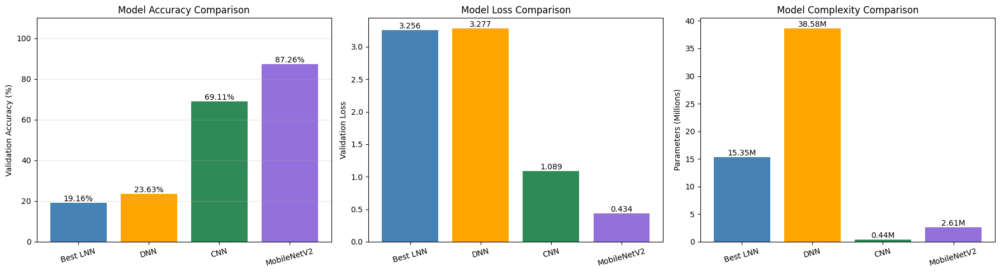

In [111]:
model_colors = [
    "steelblue",
    "orange",
    "seagreen",
    "mediumpurple"
]

plt.figure(figsize=(18, 5))

# Accuracy comparison
plt.subplot(1, 3, 1)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Validation Accuracy (%)"],
    color=model_colors
)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Validation Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 110)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

# Loss comparison
plt.subplot(1, 3, 2)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Validation Loss"],
    color=model_colors
)

plt.bar_label(bars, fmt="%.3f")
plt.ylabel("Validation Loss")
plt.title("Model Loss Comparison")
plt.xticks(rotation=15)

# Parameter comparison
plt.subplot(1, 3, 3)

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Parameters"] / 1000000,
    color=model_colors
)

plt.bar_label(bars, fmt="%.2fM")
plt.ylabel("Parameters (Millions)")
plt.title("Model Complexity Comparison")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## 11.15 Transfer Learning Accuracy Improvement Analysis

Quantifying the performance improvement achieved
through pretrained feature extraction compared
with previously trained neural network architectures.

In [112]:
print("===== ACCURACY IMPROVEMENT =====\n")

print(
    f"Over LNN: "
    f"{(transfer_val_accuracy - lnn_val_accuracy) * 100:.2f}"
    " percentage points"
)

print(
    f"Over DNN: "
    f"{(transfer_val_accuracy - dnn_val_accuracy) * 100:.2f}"
    " percentage points"
)

print(
    f"Over CNN: "
    f"{(transfer_val_accuracy - cnn_val_accuracy) * 100:.2f}"
    " percentage points"
)

best_architecture = architecture_df.loc[
    architecture_df["Validation Accuracy (%)"].idxmax()
]

print("\nBest Performing Architecture:")

print(best_architecture.to_string())

===== ACCURACY IMPROVEMENT =====

Over LNN: 68.10 percentage points
Over DNN: 63.63 percentage points
Over CNN: 18.14 percentage points

Best Performing Architecture:
Model                      MobileNetV2
Parameters                     2612134
Validation Accuracy (%)      87.257385
Validation Loss               0.433853


## 11.16 Transfer Learning Benchmark Recording and Model Saving

Recording pretrained model performance for comparison
with the upcoming fine-tuned MobileNetV2 model.

In [113]:
transfer_result = {
    "Model": "MobileNetV2 Transfer Learning",
    "Batch Size": TRANSFER_BATCH_SIZE,
    "Learning Rate": TRANSFER_LEARNING_RATE,
    "Optimizer": "adam",
    "Epochs": len(transfer_history.history["loss"]),
    "Parameters": best_transfer.count_params(),
    "Training Accuracy (%)": transfer_train_accuracy * 100,
    "Validation Accuracy (%)": transfer_val_accuracy * 100,
    "Training Loss": transfer_train_loss,
    "Validation Loss": transfer_val_loss,
    "Training Time (min)": transfer_training_time / 60
}

all_results_df = all_results_df[
    all_results_df["Model"] != "MobileNetV2 Transfer Learning"
]

all_results_df = pd.concat(
    [all_results_df, pd.DataFrame([transfer_result])],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

all_results_df.to_csv(
    model_path + "/all_model_results.csv",
    index=False
)

print("Transfer learning benchmark saved successfully!")

,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min),Optimizer
0,MobileNetV2 Transfer Learning,32,0.0010,15,2612134,94.4409,87.2574,0.1905,0.4339,7.8039,adam
1,CNN,32,0.0010,30,436390,77.1624,69.1139,0.7997,1.0890,16.0996,adam
2,DNN,32,0.0001,20,38583014,47.4578,23.6287,2.2674,3.2775,8.2789,adam
3,LNN Experiment 4,32,0.0001,15,15353958,25.2743,19.1561,3.0348,3.2556,4.8045,sgd
4,LNN Experiment 3,32,0.0005,6,15353958,29.0190,13.5021,12.6287,20.1408,1.8733,adam
5,LNN Experiment 2,64,0.0001,4,15353958,19.0084,13.5021,3.6520,4.3120,1.2684,adam
6,LNN Experiment 1,32,0.0001,4,15353958,21.2342,12.9958,4.1415,5.1505,1.3424,adam
7,Baseline LNN,32,0.0010,15,15353958,54.5570,12.5738,18.0240,58.2901,5.5630,NaN


Transfer learning benchmark saved successfully!


# 12. MobileNetV2 Fine-Tuning and Accuracy Optimization

Improving pretrained model performance by selectively
unfreezing deeper convolutional layers and adapting
pretrained features to flower classification.

## 12.1 Selective Layer Unfreezing

In [114]:
fine_tuned_model = tf.keras.models.load_model(
    model_path + "/best_transfer.keras"
)

fine_base_model = next(
    layer for layer in fine_tuned_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenet" in layer.name.lower()
)

print("Pretrained model:", fine_base_model.name)
print("Total layers:", len(fine_base_model.layers))

Pretrained model: mobilenetv2_1.00_224
Total layers: 154


In [115]:
fine_base_model.trainable = True

FINE_TUNE_LAYERS = 30

for layer in fine_base_model.layers:
    layer.trainable = False

for layer in fine_base_model.layers[-FINE_TUNE_LAYERS:]:

    if not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print(
    "Trainable base layers:",
    sum(layer.trainable for layer in fine_base_model.layers)
)

print(
    "Frozen base layers:",
    sum(not layer.trainable for layer in fine_base_model.layers)
)

Trainable base layers: 19
Frozen base layers: 135


## 12.2 Trainable Parameter Analysis

Analyzing the change in trainable and frozen parameters
after selectively unfreezing pretrained layers.

Before Fine-Tuning: 354,150
After Fine-Tuning: 1,864,870
Frozen Parameters: 747,264


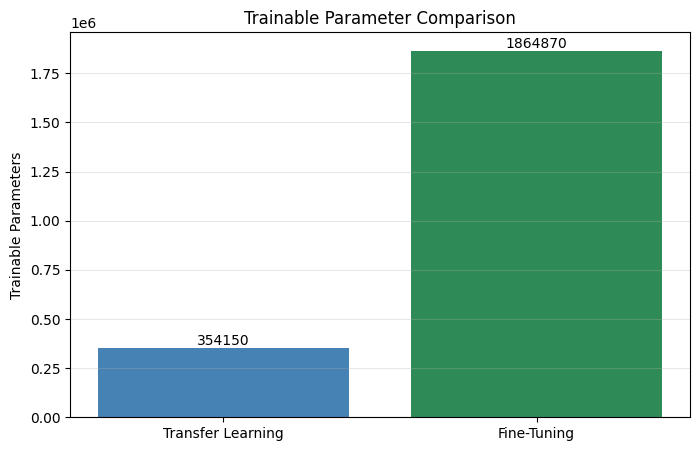

In [116]:
fine_trainable_params = sum(
    int(np.prod(w.shape))
    for w in fine_tuned_model.trainable_weights
)

fine_frozen_params = sum(
    int(np.prod(w.shape))
    for w in fine_tuned_model.non_trainable_weights
)

print(f"Before Fine-Tuning: {trainable_params:,}")
print(f"After Fine-Tuning: {fine_trainable_params:,}")
print(f"Frozen Parameters: {fine_frozen_params:,}")

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Transfer Learning", "Fine-Tuning"],
    [trainable_params, fine_trainable_params],
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.0f")
plt.ylabel("Trainable Parameters")
plt.title("Trainable Parameter Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 12.3 Fine-Tuning Hyperparameter Configuration

Using a smaller learning rate to carefully update
pretrained weights without destroying previously
learned visual features.

In [117]:
FINE_LEARNING_RATE = 0.00001
FINE_EPOCHS = 10
FINE_BATCH_SIZE = 32

fine_tuned_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")

Fine-tuning model compiled successfully!


## 12.4 MobileNetV2 Fine-Tuning Training

Training the selectively unfrozen pretrained layers
using a reduced learning rate and model checkpointing.

In [118]:
fine_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.0000001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=model_path + "/best_finetuned.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [119]:
import time

fine_start_time = time.time()

fine_history = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=fine_callbacks,
    verbose=1
)

fine_training_time = time.time() - fine_start_time

print(
    f"\nFine-Tuning Time: "
    f"{fine_training_time / 60:.2f} minutes"
)

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9165 - loss: 0.2510
Epoch 1: val_accuracy improved from None to 0.86751, saving model to /content/flower_project/models/best_finetuned.keras

Epoch 1: finished saving model to /content/flower_project/models/best_finetuned.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 36s 91ms/step - accuracy: 0.9185 - loss: 0.2425 - val_accuracy: 0.8675 - val_loss: 0.4173 - learning_rate: 1.0000e-05
Epoch 2/10
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9331 - loss: 0.2124
Epoch 2: val_accuracy improved from 0.86751 to 0.87595, saving model to /content/flower_project/models/best_finetuned.keras

Epoch 2: finished saving model to /content/flower_project/models/best_finetuned.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.9285 - loss: 0.2231 - val_accuracy: 0.8759 - val_loss: 0.4365 - learning_rate: 1.0000e-05
Epoch 3/10
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9359 - loss: 0.2100
Epoch 3: val_accuracy impr

## 12.5 Combined Training Performance Visualization

Visualizing the complete MobileNetV2 learning process
across initial transfer learning and fine-tuning stages.

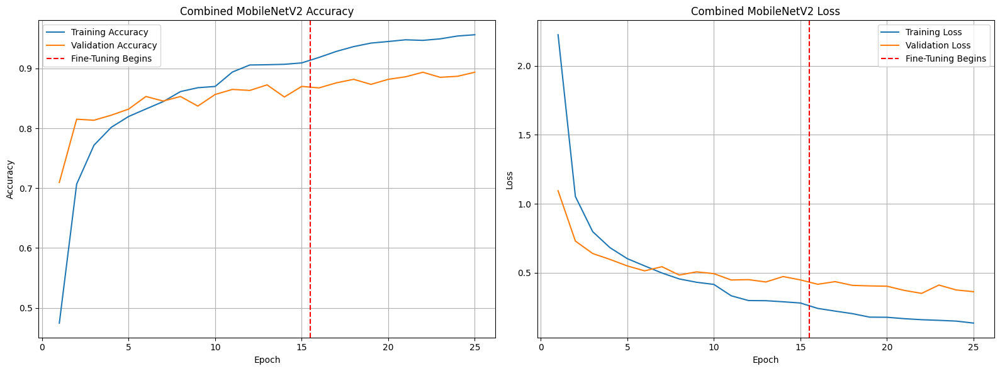

In [120]:
combined_accuracy = (
    transfer_history.history["accuracy"]
    + fine_history.history["accuracy"]
)

combined_val_accuracy = (
    transfer_history.history["val_accuracy"]
    + fine_history.history["val_accuracy"]
)

combined_loss = (
    transfer_history.history["loss"]
    + fine_history.history["loss"]
)

combined_val_loss = (
    transfer_history.history["val_loss"]
    + fine_history.history["val_loss"]
)

fine_start_epoch = len(
    transfer_history.history["accuracy"]
)

epochs_range = range(
    1, len(combined_accuracy) + 1
)

plt.figure(figsize=(16, 6))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    combined_accuracy,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    combined_val_accuracy,
    label="Validation Accuracy"
)

plt.axvline(
    fine_start_epoch + 0.5,
    color="red",
    linestyle="--",
    label="Fine-Tuning Begins"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Combined MobileNetV2 Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    combined_loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    combined_val_loss,
    label="Validation Loss"
)

plt.axvline(
    fine_start_epoch + 0.5,
    color="red",
    linestyle="--",
    label="Fine-Tuning Begins"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Combined MobileNetV2 Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 12.6 Fine-Tuned Model Performance Evaluation

Evaluating the best fine-tuned checkpoint and measuring
accuracy improvement over the frozen pretrained model.

In [121]:
best_finetuned = tf.keras.models.load_model(
    model_path + "/best_finetuned.keras"
)

fine_train_loss, fine_train_accuracy = (
    best_finetuned.evaluate(train_ds, verbose=0)
)

fine_val_loss, fine_val_accuracy = (
    best_finetuned.evaluate(val_ds, verbose=0)
)

fine_best_epoch = np.argmax(
    fine_history.history["val_accuracy"]
) + 1

print("===== FINE-TUNING RESULTS =====\n")

print(f"Training Accuracy   : {fine_train_accuracy * 100:.2f}%")
print(f"Validation Accuracy : {fine_val_accuracy * 100:.2f}%")

print(f"Training Loss       : {fine_train_loss:.4f}")
print(f"Validation Loss     : {fine_val_loss:.4f}")

print(f"Best Epoch          : {fine_best_epoch}")
print(f"Training Time       : {fine_training_time / 60:.2f} min")

fine_improvement = (
    fine_val_accuracy - transfer_val_accuracy
) * 100

print(
    f"Accuracy Improvement: "
    f"{fine_improvement:.2f} percentage points"
)

===== FINE-TUNING RESULTS =====

Training Accuracy   : 96.88%
Validation Accuracy : 89.37%
Training Loss       : 0.0973
Validation Loss     : 0.3514
Best Epoch          : 7
Training Time       : 5.11 min
Accuracy Improvement: 2.11 percentage points


,Model,Validation Accuracy (%),Validation Loss,Trainable Parameters
0,Transfer Learning,87.2574,0.4339,354150
1,Fine-Tuning,89.3671,0.3514,1864870


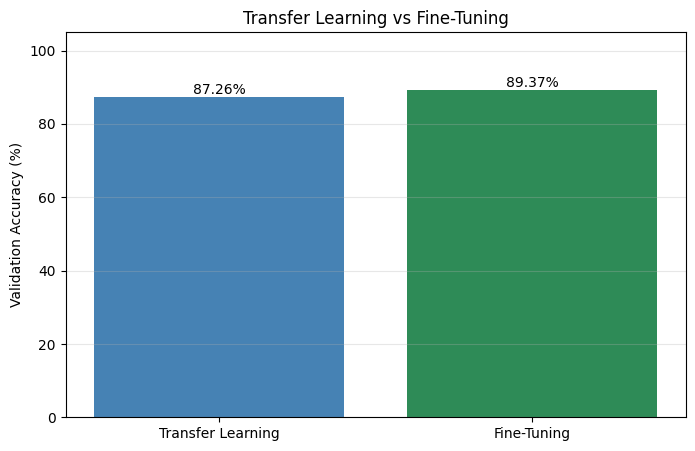

In [122]:
fine_comparison_df = pd.DataFrame([

    {
        "Model": "Transfer Learning",
        "Validation Accuracy (%)": transfer_val_accuracy * 100,
        "Validation Loss": transfer_val_loss,
        "Trainable Parameters": trainable_params
    },

    {
        "Model": "Fine-Tuning",
        "Validation Accuracy (%)": fine_val_accuracy * 100,
        "Validation Loss": fine_val_loss,
        "Trainable Parameters": fine_trainable_params
    }
])

display(fine_comparison_df.round(4))

plt.figure(figsize=(8, 5))

bars = plt.bar(
    fine_comparison_df["Model"],
    fine_comparison_df["Validation Accuracy (%)"],
    color=["steelblue", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylabel("Validation Accuracy (%)")
plt.title("Transfer Learning vs Fine-Tuning")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 12.8 Fine-Tuning Benchmark Recording

Recording the final trained model performance for
comprehensive architecture comparison and selection.

In [123]:
fine_result = {
    "Model": "MobileNetV2 Fine-Tuned",
    "Batch Size": FINE_BATCH_SIZE,
    "Learning Rate": FINE_LEARNING_RATE,
    "Optimizer": "adam",
    "Epochs": len(fine_history.history["loss"]),
    "Parameters": best_finetuned.count_params(),
    "Training Accuracy (%)": fine_train_accuracy * 100,
    "Validation Accuracy (%)": fine_val_accuracy * 100,
    "Training Loss": fine_train_loss,
    "Validation Loss": fine_val_loss,
    "Training Time (min)": fine_training_time / 60
}

all_results_df = all_results_df[
    all_results_df["Model"] != "MobileNetV2 Fine-Tuned"
]

all_results_df = pd.concat(
    [all_results_df, pd.DataFrame([fine_result])],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

all_results_df.to_csv(
    model_path + "/all_model_results.csv",
    index=False
)

print("Final training benchmark saved successfully!")

,Model,Batch Size,Learning Rate,Epochs,Parameters,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss,Training Time (min),Optimizer
0,MobileNetV2 Fine-Tuned,32,0.0000,10,2612134,96.8776,89.3671,0.0973,0.3514,5.1126,adam
1,MobileNetV2 Transfer Learning,32,0.0010,15,2612134,94.4409,87.2574,0.1905,0.4339,7.8039,adam
2,CNN,32,0.0010,30,436390,77.1624,69.1139,0.7997,1.0890,16.0996,adam
3,DNN,32,0.0001,20,38583014,47.4578,23.6287,2.2674,3.2775,8.2789,adam
4,LNN Experiment 4,32,0.0001,15,15353958,25.2743,19.1561,3.0348,3.2556,4.8045,sgd
5,LNN Experiment 3,32,0.0005,6,15353958,29.0190,13.5021,12.6287,20.1408,1.8733,adam
6,LNN Experiment 2,64,0.0001,4,15353958,19.0084,13.5021,3.6520,4.3120,1.2684,adam
7,LNN Experiment 1,32,0.0001,4,15353958,21.2342,12.9958,4.1415,5.1505,1.3424,adam
8,Baseline LNN,32,0.0010,15,15353958,54.5570,12.5738,18.0240,58.2901,5.5630,NaN


Final training benchmark saved successfully!


# 13. Final Model Evaluation and Performance Comparison

Selecting the optimal flower classification model
based on validation performance and evaluating its
generalization capability using unseen test images.

## 13.1 Overall Architecture Comparison

In [124]:
final_comparison_df = pd.DataFrame([

    {
        "Model": "Optimized LNN",
        "Parameters": best_lnn.count_params(),
        "Validation Accuracy (%)": lnn_val_accuracy * 100,
        "Validation Loss": lnn_val_loss,
        "File": "best_lnn.keras"
    },

    {
        "Model": "DNN",
        "Parameters": best_dnn.count_params(),
        "Validation Accuracy (%)": dnn_val_accuracy * 100,
        "Validation Loss": dnn_val_loss,
        "File": "best_dnn.keras"
    },

    {
        "Model": "CNN",
        "Parameters": best_cnn.count_params(),
        "Validation Accuracy (%)": cnn_val_accuracy * 100,
        "Validation Loss": cnn_val_loss,
        "File": "best_cnn.keras"
    },

    {
        "Model": "MobileNetV2 Transfer Learning",
        "Parameters": best_transfer.count_params(),
        "Validation Accuracy (%)": transfer_val_accuracy * 100,
        "Validation Loss": transfer_val_loss,
        "File": "best_transfer.keras"
    },

    {
        "Model": "MobileNetV2 Fine-Tuned",
        "Parameters": best_finetuned.count_params(),
        "Validation Accuracy (%)": fine_val_accuracy * 100,
        "Validation Loss": fine_val_loss,
        "File": "best_finetuned.keras"
    }
])

final_comparison_df = final_comparison_df.sort_values(
    by=["Validation Accuracy (%)", "Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(final_comparison_df.round(4))

,Model,Parameters,Validation Accuracy (%),Validation Loss,File
0,MobileNetV2 Fine-Tuned,2612134,89.3671,0.3514,best_finetuned.keras
1,MobileNetV2 Transfer Learning,2612134,87.2574,0.4339,best_transfer.keras
2,CNN,436390,69.1139,1.0890,best_cnn.keras
3,DNN,38583014,23.6287,3.2775,best_dnn.keras
4,Optimized LNN,15353958,19.1561,3.2556,best_lnn.keras


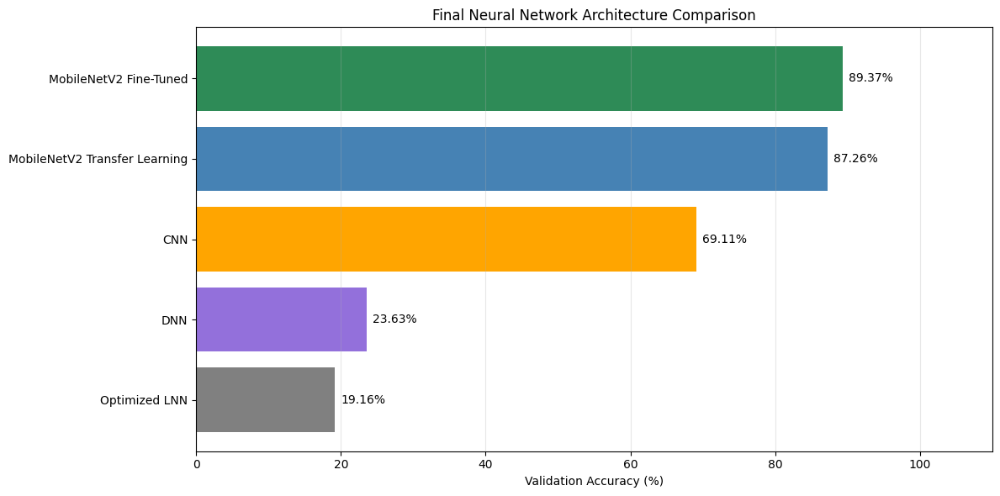

In [125]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    final_comparison_df["Model"],
    final_comparison_df["Validation Accuracy (%)"],
    color=["seagreen", "steelblue", "orange",
           "mediumpurple", "gray"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=5)

plt.xlabel("Validation Accuracy (%)")
plt.title("Final Neural Network Architecture Comparison")

plt.xlim(0, 110)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 13.2 Optimal Model Selection

Automatically selecting the best-performing model
based on validation accuracy and validation loss.

In [126]:
final_best_result = final_comparison_df.iloc[0]

FINAL_MODEL_NAME = final_best_result["Model"]

final_model = tf.keras.models.load_model(
    os.path.join(
        model_path,
        final_best_result["File"]
    )
)

print("===== FINAL SELECTED MODEL =====\n")

print("Model:", FINAL_MODEL_NAME)

print(
    f"Validation Accuracy: "
    f"{final_best_result['Validation Accuracy (%)']:.2f}%"
)

print(
    f"Validation Loss: "
    f"{final_best_result['Validation Loss']:.4f}"
)

print(f"Parameters: {final_model.count_params():,}")

===== FINAL SELECTED MODEL =====

Model: MobileNetV2 Fine-Tuned
Validation Accuracy: 89.37%
Validation Loss: 0.3514
Parameters: 2,612,134


## 13.3 Unseen Test Dataset Evaluation

Evaluating the selected model on previously unseen
flower images to measure real generalization performance.

In [127]:
test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\n===== FINAL TEST RESULTS =====\n")

print("Selected Model:", FINAL_MODEL_NAME)
print("Total Test Images:", len(test_paths))

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print(
    f"Validation Accuracy: "
    f"{final_best_result['Validation Accuracy (%)']:.2f}%"
)

38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.8828 - loss: 0.4067

===== FINAL TEST RESULTS =====

Selected Model: MobileNetV2 Fine-Tuned
Total Test Images: 1186
Test Accuracy: 88.28%
Test Loss: 0.4067
Validation Accuracy: 89.37%


## 13.4 Test Dataset Prediction Generation

Generating predicted class probabilities and comparing
predicted labels with actual flower categories.

In [128]:
y_true = []
y_prob = []

for images, labels in test_ds:

    probabilities = final_model(
        images,
        training=False
    ).numpy()

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Probability matrix shape:", y_prob.shape)

print("Correct predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))

Actual labels shape: (1186,)
Predicted labels shape: (1186,)
Probability matrix shape: (1186, 102)
Correct predictions: 1047
Incorrect predictions: 139


## 13.5 Classification Performance Metrics

Evaluating classification accuracy, precision, recall
and F1-score across all flower categories.

In [129]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)

macro_precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

print("===== CLASSIFICATION METRICS =====\n")

print(f"Accuracy        : {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"Macro Precision : {macro_precision*100:.2f}%")
print(f"Macro Recall    : {macro_recall*100:.2f}%")
print(f"Macro F1-Score  : {macro_f1*100:.2f}%")
print(f"Weighted F1     : {weighted_f1*100:.2f}%")

===== CLASSIFICATION METRICS =====

Accuracy        : 88.28%
Macro Precision : 90.70%
Macro Recall    : 86.54%
Macro F1-Score  : 87.20%
Weighted F1     : 88.24%


## 13.6 Top-1 and Top-5 Accuracy Evaluation

Measuring whether the correct flower category appears
among the model's highest probability predictions.

In [130]:
top1_accuracy = accuracy_score(
    y_true, y_pred
)

top5_accuracy = top_k_accuracy_score(
    y_true,
    y_prob,
    k=5,
    labels=np.arange(NUM_CLASSES)
)

print(f"Top-1 Accuracy: {top1_accuracy * 100:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy * 100:.2f}%")

Top-1 Accuracy: 88.28%
Top-5 Accuracy: 98.06%


## 13.7 Class-Wise Classification Report

Analyzing precision, recall, F1-score and sample
support for individual flower categories.

In [131]:
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    model_path + "/classification_report.csv"
)

,precision,recall,f1-score,support
alpine_sea_holly,1.0000,1.0000,1.0000,4.0000
anthurium,1.0000,1.0000,1.0000,11.0000
artichoke,1.0000,1.0000,1.0000,8.0000
azalea,0.6667,0.6000,0.6316,10.0000
ball_moss,1.0000,0.5000,0.6667,4.0000
...,...,...,...,...
windflower,0.8000,0.8000,0.8000,5.0000
yellow_iris,0.8000,0.8000,0.8000,5.0000
accuracy,0.8828,0.8828,0.8828,0.8828
macro avg,0.9070,0.8654,0.8720,1186.0000


## 13.8 Confusion Matrix Analysis

Visualizing correct and incorrect classifications
across all flower categories to identify commonly
confused flower species.

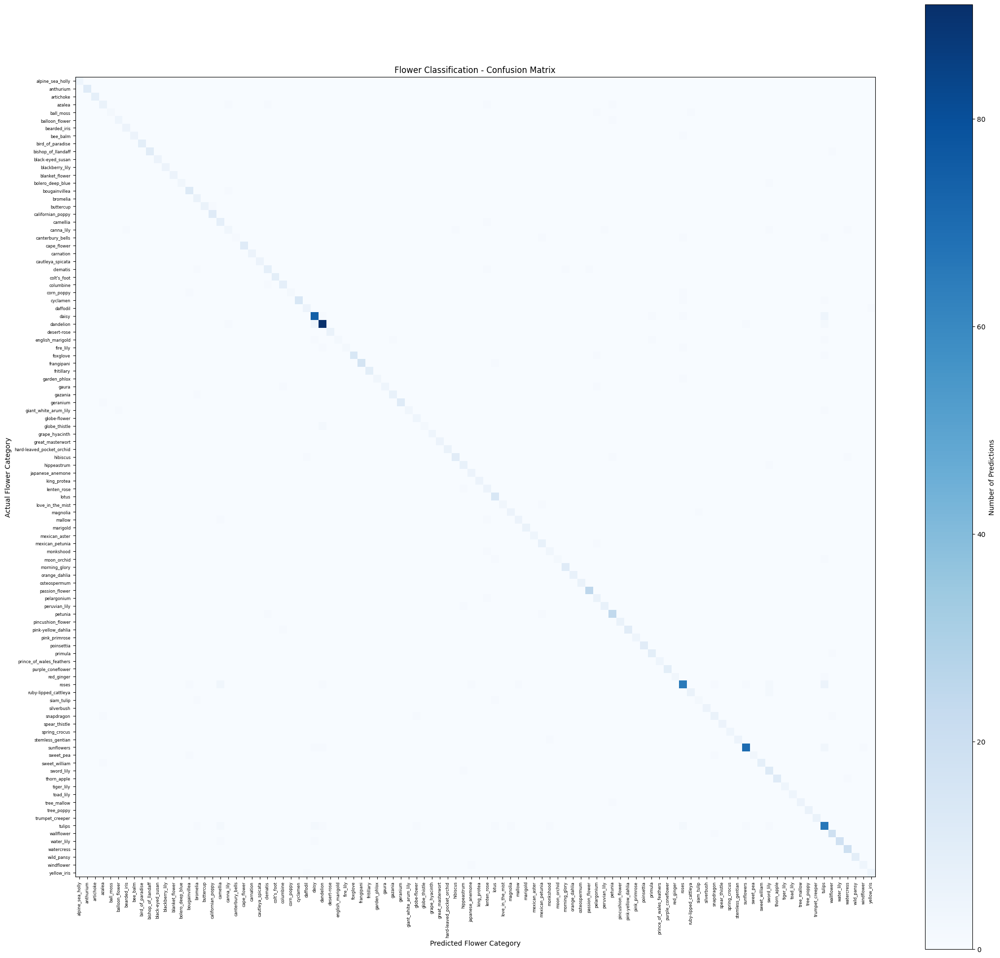

In [132]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(22, 20))

plt.imshow(
    cm,
    cmap="Blues",
    interpolation="nearest"
)

plt.colorbar(label="Number of Predictions")

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=6
)

plt.yticks(
    range(NUM_CLASSES),
    class_names,
    fontsize=6
)

plt.xlabel("Predicted Flower Category")
plt.ylabel("Actual Flower Category")
plt.title("Flower Classification - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    model_path + "/confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 13.9 Class-Wise Performance and Error Analysis

Identifying the highest and lowest performing flower
categories based on class-wise F1-scores.

In [133]:
class_performance_df = report_df.loc[
    class_names
].copy()

class_performance_df = class_performance_df.sort_values(
    by="f1-score",
    ascending=False
)

print("===== TOP 10 PERFORMING FLOWERS =====")

display(class_performance_df.head(10).round(4))

print("\n===== LOWEST 10 PERFORMING FLOWERS =====")

display(class_performance_df.tail(10).round(4))

===== TOP 10 PERFORMING FLOWERS =====


,precision,recall,f1-score,support
alpine_sea_holly,1.0,1.0,1.0,4.0
anthurium,1.0,1.0,1.0,11.0
artichoke,1.0,1.0,1.0,8.0
blackberry_lily,1.0,1.0,1.0,5.0
blanket_flower,1.0,1.0,1.0,5.0
bird_of_paradise,1.0,1.0,1.0,9.0
desert-rose,1.0,1.0,1.0,6.0
fritillary,1.0,1.0,1.0,9.0
cautleya_spicata,1.0,1.0,1.0,5.0
black-eyed_susan,1.0,1.0,1.0,5.0



===== LOWEST 10 PERFORMING FLOWERS =====


,precision,recall,f1-score,support
ball_moss,1.0000,0.5000,0.6667,4.0
fire_lily,1.0000,0.5000,0.6667,4.0
snapdragon,0.6667,0.6667,0.6667,9.0
monkshood,0.6000,0.7500,0.6667,4.0
azalea,0.6667,0.6000,0.6316,10.0
lenten_rose,0.4545,0.8333,0.5882,6.0
siam_tulip,0.6667,0.5000,0.5714,4.0
english_marigold,1.0000,0.3333,0.5000,6.0
canna_lily,0.5000,0.3750,0.4286,8.0
canterbury_bells,1.0000,0.2500,0.4000,4.0


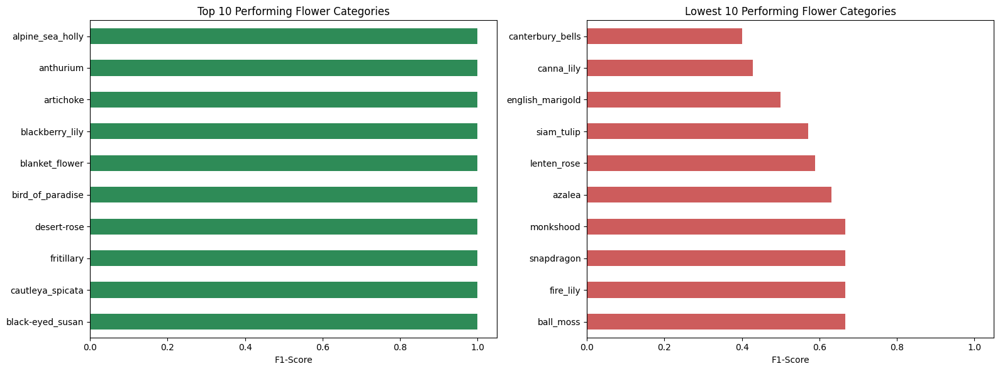

In [134]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)

class_performance_df.head(10)["f1-score"].plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Performing Flower Categories")
plt.xlabel("F1-Score")
plt.xlim(0, 1.05)
plt.gca().invert_yaxis()

plt.subplot(1, 2, 2)

class_performance_df.tail(10)["f1-score"].plot(
    kind="barh",
    color="indianred"
)

plt.title("Lowest 10 Performing Flower Categories")
plt.xlabel("F1-Score")
plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()

## 13.10 Prediction Visualization and Misclassification Analysis

Visualizing successful and unsuccessful predictions
to understand model strengths and limitations.

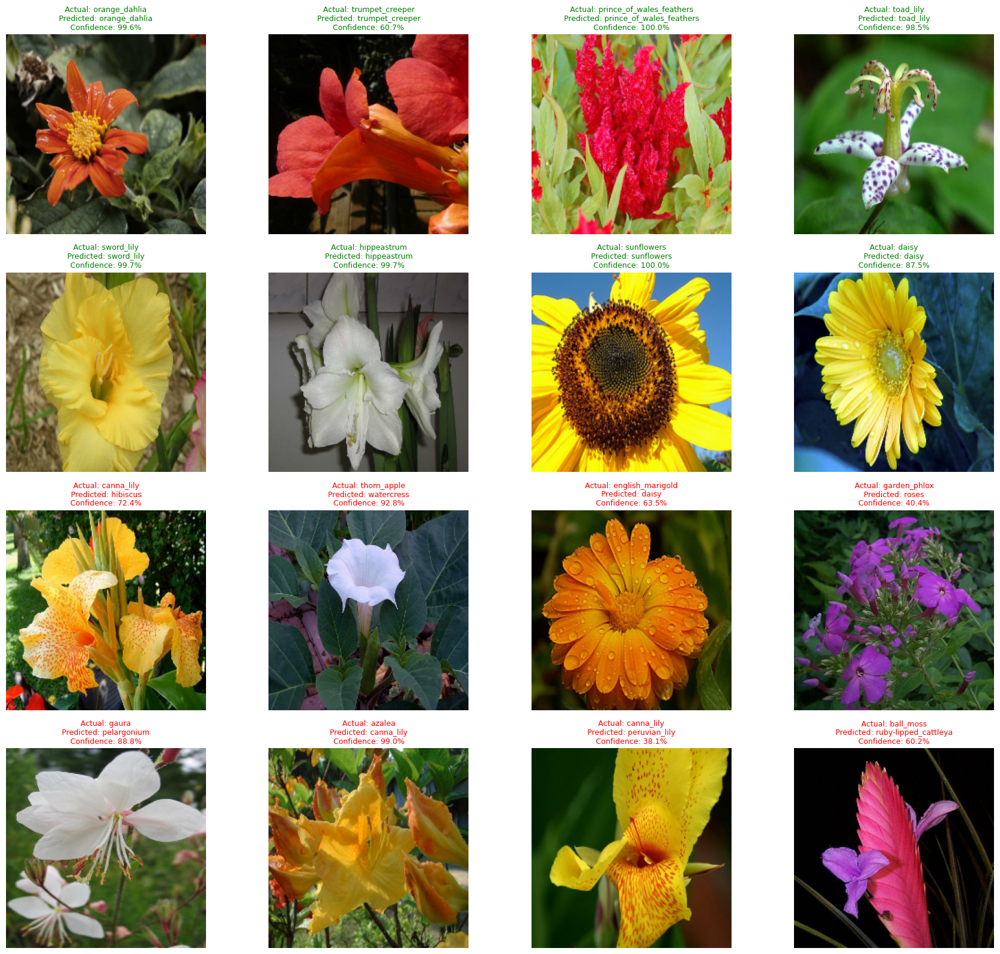

In [136]:
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

rng = np.random.default_rng(SEED)

selected_indices = np.concatenate([

    rng.choice(
        correct_indices,
        size=min(8, len(correct_indices)),
        replace=False
    ),

    rng.choice(
        incorrect_indices,
        size=min(8, len(incorrect_indices)),
        replace=False
    )
])

plt.figure(figsize=(18, 16))

for i, index in enumerate(selected_indices):

    image, label = preprocess_image(
        test_paths[index],
        test_labels[index]
    )

    actual = class_names[y_true[index]]
    predicted = class_names[y_pred[index]]

    confidence = np.max(y_prob[index]) * 100

    color = (
        "green" if y_true[index] == y_pred[index]
        else "red"
    )

    plt.subplot(4, 4, i + 1)

    plt.imshow(image.numpy())

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 13.11 Final Evaluation Summary and Results Export

Saving final model performance metrics, architecture
comparisons and classification analysis for documentation.

In [137]:
final_summary = {
    "Selected Model": FINAL_MODEL_NAME,
    "Number of Classes": NUM_CLASSES,
    "Training Images": len(train_paths),
    "Validation Images": len(val_paths),
    "Testing Images": len(test_paths),
    "Image Dimensions": "224 x 224 x 3",
    "Model Parameters": final_model.count_params(),
    "Validation Accuracy (%)":
        float(final_best_result["Validation Accuracy (%)"]),
    "Test Accuracy (%)": float(test_accuracy * 100),
    "Test Loss": float(test_loss),
    "Macro Precision (%)": float(macro_precision * 100),
    "Macro Recall (%)": float(macro_recall * 100),
    "Macro F1-Score (%)": float(macro_f1 * 100),
    "Weighted F1-Score (%)": float(weighted_f1 * 100),
    "Top-5 Accuracy (%)": float(top5_accuracy * 100)
}

final_summary_df = pd.DataFrame(
    list(final_summary.items()),
    columns=["Metric", "Value"]
)

display(final_summary_df)

final_summary_df.to_csv(
    model_path + "/final_evaluation_summary.csv",
    index=False
)

final_comparison_df.to_csv(
    model_path + "/final_architecture_comparison.csv",
    index=False
)

print("Final evaluation results saved successfully!")

,Metric,Value
0,Selected Model,MobileNetV2 Fine-Tuned
1,Number of Classes,102
2,Training Images,9480
3,Validation Images,1185
4,Testing Images,1186
5,Image Dimensions,224 x 224 x 3
6,Model Parameters,2612134
7,Validation Accuracy (%),89.367086
8,Test Accuracy (%),88.279933
9,Test Loss,0.406744


Final evaluation results saved successfully!


# 14. Custom Image Prediction and Model Deployment

Implementing real-world flower image classification,
confidence-based prediction, model serialization
and project artifact export.

## 14.1 Final Model Saving

In [138]:
import os
import json

FINAL_MODEL_PATH = os.path.join(
    model_path,
    "final_flower_classifier.keras"
)

final_model.save(FINAL_MODEL_PATH)

with open(model_path + "/class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

model_size = os.path.getsize(FINAL_MODEL_PATH) / (1024 ** 2)

print("Model:", FINAL_MODEL_NAME)
print("Total Classes:", NUM_CLASSES)
print(f"Model Size: {model_size:.2f} MB")
print("Saved Path:", FINAL_MODEL_PATH)

Model: MobileNetV2 Fine-Tuned
Total Classes: 102
Model Size: 24.78 MB
Saved Path: /content/flower_project/models/final_flower_classifier.keras


## 14.2 Custom Image Loading and Preprocessing

Converting externally uploaded flower images into
normalized RGB tensors compatible with the trained model.

In [139]:
from PIL import Image

def prepare_custom_image(image_path):

    image = Image.open(image_path).convert("RGB")

    image = image.resize((IMG_WIDTH, IMG_HEIGHT))

    image_array = np.array(
        image, dtype=np.float32
    ) / 255.0

    input_tensor = np.expand_dims(
        image_array, axis=0
    )

    return image_array, input_tensor

## 14.3 Flower Classification and Top-5 Predictions

Implementing a reusable prediction function that
identifies flower categories and displays the five
highest probability predictions.

In [140]:
def predict_flower(image_path, top_k=5):

    image, input_tensor = prepare_custom_image(
        image_path
    )

    probabilities = final_model.predict(
        input_tensor,
        verbose=0
    )[0]

    top_indices = np.argsort(
        probabilities
    )[-top_k:][::-1]

    predicted_class = class_names[top_indices[0]]

    confidence = probabilities[top_indices[0]] * 100

    plt.figure(figsize=(14, 5))

    # Display uploaded image
    plt.subplot(1, 2, 1)

    plt.imshow(image)

    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    # Top-5 probability visualization
    plt.subplot(1, 2, 2)

    names = [
        class_names[i] for i in top_indices
    ]

    scores = probabilities[top_indices] * 100

    bars = plt.barh(
        names,
        scores,
        color="steelblue"
    )

    bars[0].set_color("seagreen")

    plt.bar_label(bars, fmt="%.2f%%")

    plt.xlim(0, 115)
    plt.gca().invert_yaxis()

    plt.xlabel("Confidence (%)")
    plt.title("Top-5 Flower Predictions")

    plt.tight_layout()
    plt.show()

    print("===== PREDICTION RESULTS =====")

    for rank, index in enumerate(top_indices, 1):

        print(
            f"{rank}. {class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )

    if confidence < 50:
        print("\nWarning: Low prediction confidence.")

    return predicted_class, confidence

## 14.4 Real-World Flower Image Classification

Testing the trained model using externally uploaded
flower images that were not part of the training dataset.

Saving download (1).jpeg to download (1).jpeg

Uploaded Image: download (1).jpeg


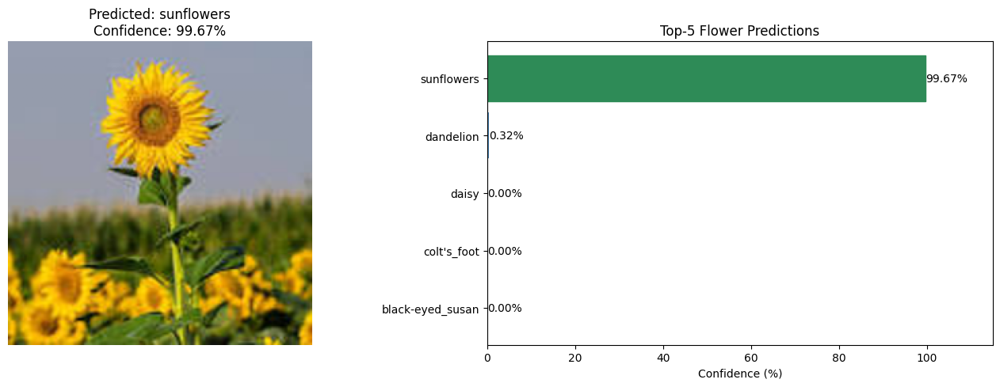

===== PREDICTION RESULTS =====
1. sunflowers: 99.67%
2. dandelion: 0.32%
3. daisy: 0.00%
4. colt's_foot: 0.00%
5. black-eyed_susan: 0.00%


In [141]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():

    print("\nUploaded Image:", filename)

    predicted_class, confidence = predict_flower(
        filename
    )

## 14.5 Model Metadata and Configuration Export

Preserving model architecture information,
preprocessing requirements and evaluation metrics
for future application integration.

In [142]:
metadata = {
    "project_name": "Flower Classification",
    "model_name": str(FINAL_MODEL_NAME),
    "model_file": "final_flower_classifier.keras",
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "input_shape": [224, 224, 3],
    "color_mode": "RGB",
    "normalization": "0-1",
    "num_classes": int(NUM_CLASSES),
    "class_names": class_names,
    "parameters": int(final_model.count_params()),
    "validation_accuracy": float(
        final_best_result["Validation Accuracy (%)"]
    ),
    "test_accuracy": float(test_accuracy * 100),
    "macro_f1_score": float(macro_f1 * 100),
    "top5_accuracy": float(top5_accuracy * 100)
}

with open(model_path + "/model_metadata.json", "w") as f:

    json.dump(metadata, f, indent=4)

print(json.dumps(metadata, indent=4))

{
    "project_name": "Flower Classification",
    "model_name": "MobileNetV2 Fine-Tuned",
    "model_file": "final_flower_classifier.keras",
    "framework": "TensorFlow/Keras",
    "tensorflow_version": "2.21.0",
    "input_shape": [
        224,
        224,
        3
    ],
    "color_mode": "RGB",
    "normalization": "0-1",
    "num_classes": 102,
    "class_names": [
        "alpine_sea_holly",
        "anthurium",
        "artichoke",
        "azalea",
        "ball_moss",
        "balloon_flower",
        "bearded_iris",
        "bee_balm",
        "bird_of_paradise",
        "bishop_of_llandaff",
        "black-eyed_susan",
        "blackberry_lily",
        "blanket_flower",
        "bolero_deep_blue",
        "bougainvillea",
        "bromelia",
        "buttercup",
        "californian_poppy",
        "camellia",
        "canna_lily",
        "canterbury_bells",
        "cape_flower",
        "carnation",
        "cautleya_spicata",
        "clematis",
        "colt's_foot

## 14.6 Saved Model Reload and Integrity Verification

Verifying that the exported model can be loaded
independently and produces consistent predictions
without retraining.

In [143]:
reloaded_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

with open(model_path + "/class_names.json") as f:

    reloaded_classes = json.load(f)

for images, labels in test_ds.take(1):

    original_output = final_model(
        images,
        training=False
    ).numpy()

    reloaded_output = reloaded_model(
        images,
        training=False
    ).numpy()

print(
    "Prediction Consistency:",
    np.allclose(
        original_output,
        reloaded_output,
        atol=1e-5
    )
)

print(
    "Class Mapping Consistency:",
    reloaded_classes == class_names
)

print("Input Shape:", reloaded_model.input_shape)
print("Output Shape:", reloaded_model.output_shape)

Prediction Consistency: True
Class Mapping Consistency: True
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 102)


## 14.7 Project Artifact Packaging and Export

Packaging the trained model, classification reports,
evaluation metrics and configuration files into a
portable deployment package.

In [144]:
import shutil

export_path = "/content/flower_classifier_export"

os.makedirs(export_path, exist_ok=True)

export_files = [

    "final_flower_classifier.keras",
    "class_names.json",
    "model_metadata.json",
    "classification_report.csv",
    "confusion_matrix.png",
    "final_evaluation_summary.csv",
    "final_architecture_comparison.csv",
    "all_model_results.csv",
    "hyperparameter_results.csv"

]

for filename in export_files:

    source = os.path.join(model_path, filename)

    if os.path.exists(source):

        shutil.copy2(source, export_path)

        print("Exported:", filename)

    else:

        print("Missing:", filename)

zip_path = shutil.make_archive(
    "/content/flower_classifier_export",
    "zip",
    export_path
)

print("\nExport Package:", zip_path)

print(
    f"ZIP Size: "
    f"{os.path.getsize(zip_path) / (1024 ** 2):.2f} MB"
)

Exported: final_flower_classifier.keras
Exported: class_names.json
Exported: model_metadata.json
Exported: classification_report.csv
Exported: confusion_matrix.png
Exported: final_evaluation_summary.csv
Exported: final_architecture_comparison.csv
Exported: all_model_results.csv
Exported: hyperparameter_results.csv

Export Package: /content/flower_classifier_export.zip
ZIP Size: 22.47 MB


## 14.8 Permanent Google Drive Backup

Backing up trained neural network models and
evaluation artifacts to persistent cloud storage.

In [145]:
from google.colab import drive

drive.mount("/content/drive")

backup_path = (
    "/content/drive/MyDrive/Flower_Classification_Project"
)

os.makedirs(backup_path, exist_ok=True)

shutil.copytree(
    model_path,
    os.path.join(backup_path, "models"),
    dirs_exist_ok=True
)

shutil.copy2(
    zip_path,
    backup_path
)

print("Google Drive backup completed!")
print("Backup location:", backup_path)

Mounted at /content/drive
Google Drive backup completed!
Backup location: /content/drive/MyDrive/Flower_Classification_Project


In [146]:
from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [147]:
print("=" * 60)
print("       FLOWER CLASSIFICATION PROJECT")
print("=" * 60)

print(f"Total Flower Classes : {NUM_CLASSES}")

print(
    f"Total Dataset Images : "
    f"{len(train_paths) + len(val_paths) + len(test_paths)}"
)

print(f"Best Architecture    : {FINAL_MODEL_NAME}")

print(
    f"Baseline Accuracy    : "
    f"{baseline_accuracy:.2f}%"
)

print(
    f"Validation Accuracy  : "
    f"{final_best_result['Validation Accuracy (%)']:.2f}%"
)

print(f"Final Test Accuracy  : {test_accuracy * 100:.2f}%")
print(f"Top-5 Accuracy       : {top5_accuracy * 100:.2f}%")
print(f"Macro F1-Score       : {macro_f1 * 100:.2f}%")

print(
    f"Validation Improvement: "
    f"{final_best_result['Validation Accuracy (%)'] - baseline_accuracy:.2f}"
    " percentage points"
)

print(f"Final Model Size     : {model_size:.2f} MB")

print("=" * 60)
print("          PROJECT COMPLETED")
print("=" * 60)

       FLOWER CLASSIFICATION PROJECT
Total Flower Classes : 102
Total Dataset Images : 11851
Best Architecture    : MobileNetV2 Fine-Tuned
Baseline Accuracy    : 12.57%
Validation Accuracy  : 89.37%
Final Test Accuracy  : 88.28%
Top-5 Accuracy       : 98.06%
Macro F1-Score       : 87.20%
Validation Improvement: 76.79 percentage points
Final Model Size     : 24.78 MB
          PROJECT COMPLETED


In [148]:
baseline_accuracy = float(
    results_df.iloc[0]["Validation Accuracy (%)"]
)